# ✅ Checkpoint Saving Setup for Kaggle
Run this cell FIRST before any training to set up saving paths.

In [1]:
import os
import shutil
from pathlib import Path

# ─── Kaggle Output Directory (persists after session ends) ───
SAVE_DIR = Path("/kaggle/working/saved_checkpoints")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

print(f"✅ Checkpoint save directory ready: {SAVE_DIR}")

✅ Checkpoint save directory ready: /kaggle/working/saved_checkpoints


## Step 1 — Install & Download Dataset

In [2]:
!pip -q install roboflow ultralytics

from roboflow import Roboflow
rf = Roboflow(api_key="E5GHF0z58MbGLONGk5VF")
project = rf.workspace("aziz-jda2k").project("corn-leaf-disease-hgosu")
version = project.version(17)
dataset = version.download("yolov8")
print(dataset.location)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 184.0/184.0 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 38.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 45.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 58.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 108.4 MB/s eta 0:00:0000:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 1.25.1 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.
gcsfs 2025.3.0 requires fsspec==2025.3.0, but you have fsspec 2026.2.0 which is incompatible.
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Corn-Leaf-Disease-17 in yolov8:: 100%|██████████| 21754/21754 [00:02<00:00, 8086.50it/s] 


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
/kaggle/working/Corn-Leaf-Disease-17


## Step 2 — Baseline YOLOv8 Training + Save Checkpoint

In [3]:
from ultralytics import YOLO

baseline_model = YOLO("yolov8n.pt")

baseline_model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=100,
    imgsz=640,
    batch=16,
    name="baseline",
    save=True,
    save_period=10,
)

# ─── Copy weights to /kaggle/working/saved_checkpoints/ ───
baseline_weights_dir = Path("/kaggle/working/runs/detect/baseline/weights")
baseline_save_dir = SAVE_DIR / "baseline"
baseline_save_dir.mkdir(parents=True, exist_ok=True)

for weight_file in baseline_weights_dir.glob("*.pt"):
    shutil.copy(weight_file, baseline_save_dir / weight_file.name)
    print(f"✅ Saved: {baseline_save_dir / weight_file.name}")

print(f"\n📦 Baseline checkpoints saved to: {baseline_save_dir}")
print("Files:", list(baseline_save_dir.iterdir()))

Ultralytics 8.4.42 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/Corn-Leaf-Disease-17/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mas

## Step 3 — Baseline Validation & Inference

In [4]:
baseline_model.val(
    data=f"{dataset.location}/data.yaml",
    split="test"
)

Ultralytics 8.4.42 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1175.7±395.3 MB/s, size: 57.5 KB)
val: Scanning /kaggle/working/Corn-Leaf-Disease-17/test/labels... 417 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 417/417 1.3Kit/s 0.3s<0.0s
val: New cache created: /kaggle/working/Corn-Leaf-Disease-17/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 6.6it/s 4.1s0.1s
                   all        417        419      0.971      0.964      0.983      0.904
                blight        133        134      0.991      0.933      0.986      0.818
           common_rust        131        132      0.968          1      0.989      0.897
             gray_spot         53         53      0.929      0.925      0.963      0.907
                health        100     

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7e872c167ce0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0

Results saved to /kaggle/working/runs/detect/baseline_preds


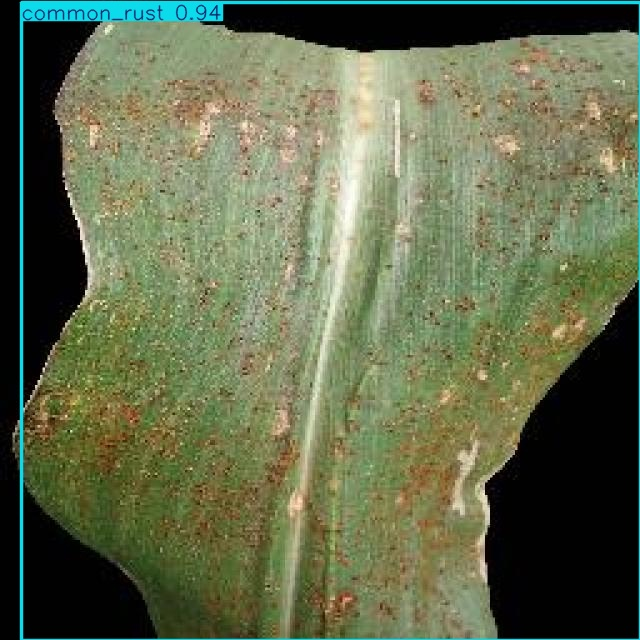

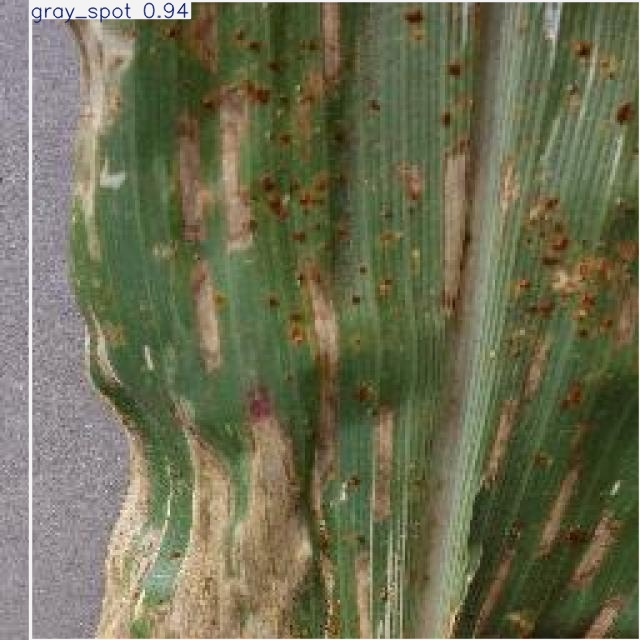

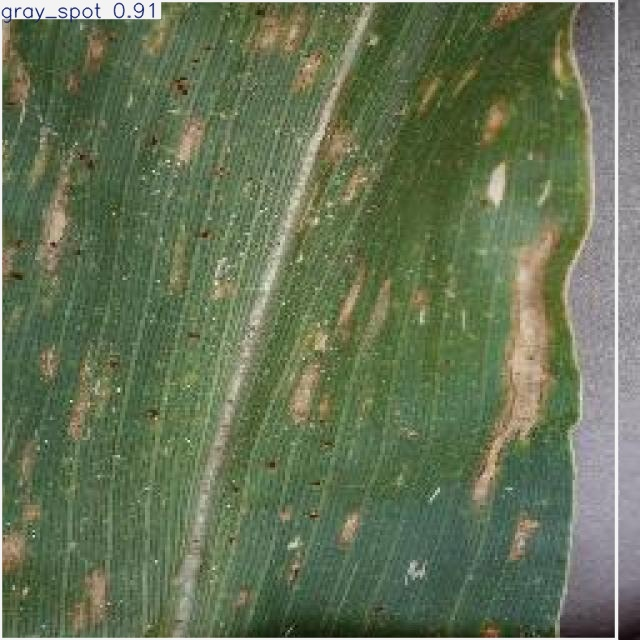

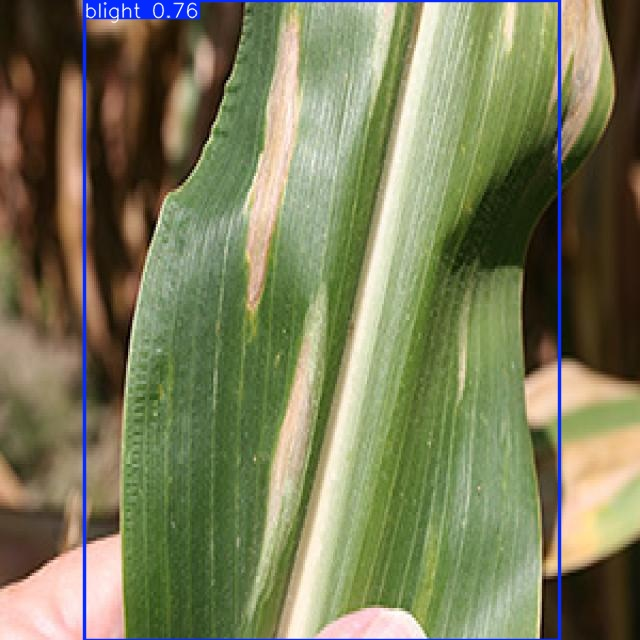

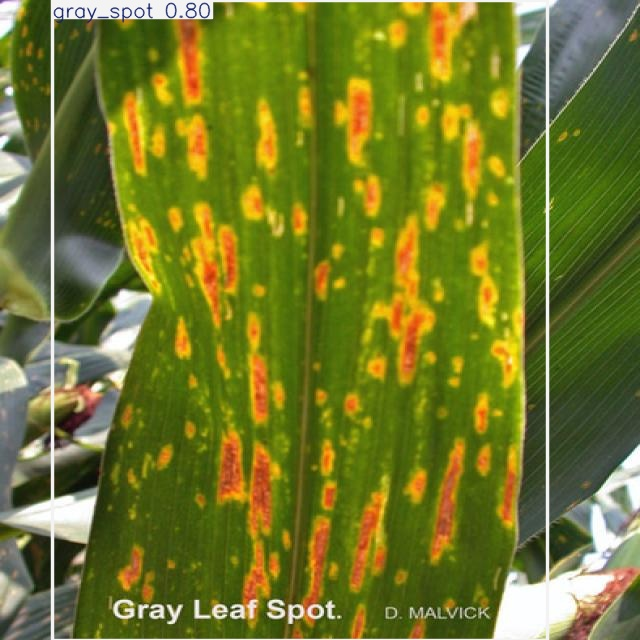

In [5]:
import os
results = baseline_model.predict(
    source=f"{dataset.location}/test/images",
    save=True,
    name="baseline_preds",
    verbose=False
)

from IPython.display import Image, display
pred_path = "/kaggle/working/runs/detect/baseline_preds"
imgs = os.listdir(pred_path)
for img in imgs[:5]:
    display(Image(filename=os.path.join(pred_path, img)))

## Step 4 — Build Custom GAF-Net Architecture

In [6]:
from pathlib import Path

yaml_text = """
nc: 4
scales:
  n: [0.33, 0.25, 1024]

backbone:
  - [-1, 1, Conv, [64, 3, 2]]
  - [-1, 1, Conv, [128, 3, 2]]
  - [-1, 3, C2f, [128, True]]
  - [-1, 1, Conv, [256, 3, 2]]
  - [-1, 6, C2f, [256, True]]
  - [-1, 1, Conv, [512, 3, 2]]
  - [-1, 6, C2f, [512, True]]
  - [-1, 1, Conv, [1024, 3, 2]]
  - [-1, 3, C2f, [1024, True]]
  - [-1, 1, SPPF, [1024, 5]]

head:
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 6], 1, Concat, [1]]
  - [-1, 3, GSConv, [512]]

  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 4], 1, Concat, [1]]
  - [-1, 3, GSConv, [256]]

  - [-1, 1, GSConv, [256, 3, 2]]
  - [[-1, 12], 1, Concat, [1]]
  - [-1, 3, GSConv, [512]]

  - [-1, 1, GSConv, [512, 3, 2]]
  - [[-1, 9], 1, Concat, [1]]
  - [-1, 3, GSConv, [1024]]

  - [[15, 18, 21], 1, FASFF, [256, 0]]
  - [[15, 18, 21], 1, FASFF, [256, 1]]
  - [[15, 18, 21], 1, FASFF, [256, 2]]

  - [[22, 23, 24], 1, Detect, [nc]]
"""

Path("/kaggle/working/yolov8_gafnet.yaml").write_text(yaml_text)
print("Saved /kaggle/working/yolov8_gafnet.yaml")

Saved /kaggle/working/yolov8_gafnet.yaml


In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from ultralytics.nn import tasks

# ─── 1. Custom Modules ───

class GSConv(nn.Module):
    """Grouped Spatial Convolution from the GAF-Net paper."""
    def __init__(self, c1, c2=None, k=3, s=1):
        super().__init__()
        if c2 is None:
            c2 = c1
        c_ = c2 // 2
        self.cv1 = nn.Conv2d(c1, c_, 1, s)
        self.dw  = nn.Conv2d(c_, c_, k, 1, padding=k // 2, groups=c_)
        self.bn  = nn.BatchNorm2d(c_)
        self.act = nn.SiLU()

    def forward(self, x):
        x1 = self.cv1(x)
        x2 = self.act(self.bn(self.dw(x1)))
        y = torch.cat((x1, x2), dim=1)
        b, c, h, w = y.shape
        y = y.reshape(b, 2, c // 2, h, w).permute(0, 2, 1, 3, 4).reshape(b, c, h, w)
        return y


class FASFF(nn.Module):
    """Feature-Adaptive Spatial Feature Fusion."""
    def __init__(self, c1, c2=256, level=0):
        super().__init__()
        if isinstance(c1, int):
            c1 = [c1, c1, c1]
        self.level = level
        self.c2 = c2
        self.reduce = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(ci, c2, 1, 1, bias=False),
                nn.BatchNorm2d(c2),
                nn.SiLU(),
            ) for ci in c1
        ])
        self.weight_layers = nn.ModuleList([
            nn.Conv2d(c2, 1, 1, 1, 0) for _ in range(3)
        ])

    def _resize_to(self, x, size):
        if x.shape[-2:] == size:
            return x
        if x.shape[-2] > size[0] or x.shape[-1] > size[1]:
            return F.adaptive_avg_pool2d(x, size)
        return F.interpolate(x, size=size, mode="nearest")

    def forward(self, x):
        assert isinstance(x, (list, tuple)) and len(x) == 3
        target_size = x[self.level].shape[-2:]
        feats = [self.reduce[i](self._resize_to(x[i], target_size)) for i in range(3)]
        weights = torch.stack([self.weight_layers[i](feats[i]) for i in range(3)], dim=0)
        weights = torch.softmax(weights, dim=0)
        fused = weights[0] * feats[0] + weights[1] * feats[1] + weights[2] * feats[2]
        return fused


def _get_out_channels(module):
    if isinstance(module, GSConv):
        return module.cv1.out_channels * 2
    if isinstance(module, nn.Sequential) and len(module) > 0:
        return _get_out_channels(module[-1])
    if hasattr(module, 'cv2'):
        return _get_out_channels(module.cv2)
    if hasattr(module, 'conv') and isinstance(module.conv, nn.Conv2d):
        return module.conv.out_channels
    for child in reversed(list(module.children())):
        result = _get_out_channels(child)
        if result is not None:
            return result
    return None


# ─── 2. Register modules ───
tasks.GSConv = GSConv
tasks.FASFF  = FASFF

# ─── 3. Monkey-patch parse_model ───
if not hasattr(tasks, '_original_parse_model'):
    tasks._original_parse_model = tasks.parse_model

def patched_parse_model(d, ch, verbose=True):
    from copy import deepcopy
    d2 = deepcopy(d)

    fasff_info = []
    gsconv_info = []
    for section in ("backbone", "head"):
        for i, layer in enumerate(d2.get(section, [])):
            f, n, m_name, args = layer
            if m_name == "FASFF":
                fasff_info.append((section, i, f, args, n))
                d2[section][i] = [-1, 1, "Conv", [args[0], 1, 1]]
            elif m_name == "GSConv":
                gsconv_info.append((section, i, f, args, n))
                d2[section][i] = [f, n, "Conv", args]

    model, save = tasks._original_parse_model(d2, ch, verbose)

    if not gsconv_info and not fasff_info:
        return model, save

    backbone_len = len(d.get("backbone", []))

    for section, idx, from_val, orig_args, n in gsconv_info:
        global_idx = idx if section == "backbone" else backbone_len + idx
        dummy = model[global_idx]
        if isinstance(dummy, nn.Sequential):
            conv_mod = dummy[0]
        else:
            conv_mod = dummy
        c1_actual = conv_mod.conv.in_channels
        c2_actual = conv_mod.conv.out_channels
        k = orig_args[1] if len(orig_args) > 1 else 3
        s = orig_args[2] if len(orig_args) > 2 else 1
        n_actual = len(dummy) if isinstance(dummy, nn.Sequential) else 1
        if n_actual > 1:
            gs = nn.Sequential(*(
                GSConv(c1_actual if j == 0 else c2_actual, c2_actual, k, s if j == 0 else 1)
                for j in range(n_actual)
            ))
        else:
            gs = GSConv(c1_actual, c2_actual, k, s)
        gs.i = global_idx
        gs.f = from_val
        gs.type = "GSConv"
        gs.np = sum(p.numel() for p in gs.parameters())
        model[global_idx] = gs

    for section, idx, from_val, args, n in fasff_info:
        global_idx = idx if section == "backbone" else backbone_len + idx
        if isinstance(from_val, list):
            input_chs = [_get_out_channels(model[fi]) for fi in from_val]
        else:
            input_chs = [_get_out_channels(model[from_val])] * 3
        actual_c2 = _get_out_channels(model[global_idx])
        level = args[1] if len(args) > 1 else 0
        fasff = FASFF(input_chs, actual_c2, level)
        fasff.i = global_idx
        fasff.f = from_val
        fasff.type = "FASFF"
        fasff.np = sum(p.numel() for p in fasff.parameters())
        model[global_idx] = fasff
        if isinstance(from_val, list):
            for fidx in from_val:
                real = fidx if fidx >= 0 else global_idx + fidx
                if real not in save:
                    save.append(real)

    return model, save

tasks.parse_model = patched_parse_model
print("✅ Custom modules registered")

✅ Custom modules registered


## Step 5 — Train GAF-Net + Save Checkpoints

In [8]:
from ultralytics import YOLO

model = YOLO("/kaggle/working/yolov8_gafnet.yaml")
model.load("yolov8n.pt")

results = model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=100,
    imgsz=640,
    batch=16,
    optimizer="SGD",
    lr0=0.01,
    weight_decay=0.0005,
    name="gafnet_corn",
    save=True,
    save_period=10,
)

# ─── Copy all weights to persistent saved_checkpoints folder ───
gafnet_weights_dir = Path("/kaggle/working/runs/detect/gafnet_corn/weights")
gafnet_save_dir = SAVE_DIR / "gafnet_corn"
gafnet_save_dir.mkdir(parents=True, exist_ok=True)

for weight_file in gafnet_weights_dir.glob("*.pt"):
    dest = gafnet_save_dir / weight_file.name
    shutil.copy(weight_file, dest)
    print(f"✅ Saved: {dest}")

shutil.copy("/kaggle/working/yolov8_gafnet.yaml", gafnet_save_dir / "yolov8_gafnet.yaml")

print(f"\n📦 GAF-Net checkpoints saved to: {gafnet_save_dir}")
print("Files:", [f.name for f in gafnet_save_dir.iterdir()])

WARNING ⚠️ no model scale passed. Assuming scale='n'.
Transferred 164/373 items from pretrained weights
Ultralytics 8.4.42 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/Corn-Leaf-Disease-17/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/yolov8_gafnet.yaml, moment

adaptive_avg_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)


      1/100      2.06G      1.679      2.133      2.791          9        640: 100% ━━━━━━━━━━━━ 628/628 5.0it/s 2:05<0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 2.0it/s 6.9s0.2s
                   all        419        420      0.574      0.895      0.751      0.599

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      2/100      2.22G       0.84      1.079      1.957         48        640: 0% ──────────── 0/628  0.2s

adaptive_avg_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)


      2/100      2.22G     0.7287      1.099      1.531          8        640: 100% ━━━━━━━━━━━━ 628/628 5.9it/s 1:47<0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 6.0it/s 2.3s0.2s
                   all        419        420      0.647      0.882       0.68      0.598

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/100      2.22G     0.6517     0.9327      1.343         51        640: 0% ──────────── 0/628  0.2s

...

     98/100      2.22G     0.1871     0.1617      1.081          3        640: 100% ━━━━━━━━━━━━ 628/628 6.0it/s 1:44<0.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 6.0it/s 2.3s0.2s
                   all        419        420      0.928      0.952      0.973       0.91

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
     99/100      2.22G     0.1184    0.08895      1.037         16        640: 0% ──────────── 0/628  0.2s

adaptive_avg_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)


     99/100      2.22G     0.1871     0.1605       1.08          3        640: 100% ━━━━━━━━━━━━ 628/628 6.0it/s 1:44<0.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 6.2it/s 2.3s0.2s
                   all        419        420      0.927      0.954      0.973      0.912

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
    100/100      2.22G     0.2873     0.1828      1.179         16        640: 0% ──────────── 0/628  0.2s

adaptive_avg_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)


    100/100      2.22G     0.1869     0.1558      1.076          3        640: 100% ━━━━━━━━━━━━ 628/628 6.0it/s 1:44<0.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 6.4it/s 2.2s0.2s
                   all        419        420      0.925      0.954      0.973      0.913

100 epochs completed in 3.004 hours.
Optimizer stripped from /kaggle/working/runs/detect/gafnet_corn/weights/last.pt, 4.1MB
Optimizer stripped from /kaggle/working/runs/detect/gafnet_corn/weights/best.pt, 4.1MB

Validating /kaggle/working/runs/detect/gafnet_corn/weights/best.pt...
Ultralytics 8.4.42 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8_gafnet summary: 115 layers, 1,921,701 parameters, 0 gradients, 6.5 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 4.1it/s 3.4s0.2s
                   all        419        420      0.927      0.954      0.973 

## Step 6 — Verify Saved Checkpoints

In [9]:
print("=== Saved Checkpoints ===")
for f in sorted(SAVE_DIR.rglob("*.pt")):
    size_mb = f.stat().st_size / (1024 * 1024)
    print(f"  {f.relative_to(SAVE_DIR)}  ({size_mb:.1f} MB)")

=== Saved Checkpoints ===
  baseline/best.pt  (6.0 MB)
  baseline/epoch0.pt  (17.5 MB)
  baseline/epoch10.pt  (17.5 MB)
  baseline/epoch20.pt  (17.5 MB)
  baseline/epoch30.pt  (17.5 MB)
  baseline/epoch40.pt  (17.5 MB)
  baseline/epoch50.pt  (17.5 MB)
  baseline/epoch60.pt  (17.5 MB)
  baseline/epoch70.pt  (17.5 MB)
  baseline/epoch80.pt  (17.5 MB)
  baseline/epoch90.pt  (17.5 MB)
  baseline/last.pt  (6.0 MB)
  gafnet_corn/best.pt  (3.9 MB)
  gafnet_corn/epoch0.pt  (7.6 MB)
  gafnet_corn/epoch10.pt  (7.6 MB)
  gafnet_corn/epoch20.pt  (7.6 MB)
  gafnet_corn/epoch30.pt  (7.6 MB)
  gafnet_corn/epoch40.pt  (7.6 MB)
  gafnet_corn/epoch50.pt  (7.7 MB)
  gafnet_corn/epoch60.pt  (7.7 MB)
  gafnet_corn/epoch70.pt  (7.7 MB)
  gafnet_corn/epoch80.pt  (7.7 MB)
  gafnet_corn/epoch90.pt  (7.7 MB)
  gafnet_corn/last.pt  (3.9 MB)


## Step 7 — Load from Checkpoint & Evaluate

In [10]:
# Load best checkpoint
best_ckpt = str(SAVE_DIR / "gafnet_corn" / "best.pt")
print(f"Loading from: {best_ckpt}")

gaf_model = YOLO(best_ckpt)

test_metrics = gaf_model.val(data=f"{dataset.location}/data.yaml", split="test")
print(test_metrics)

Loading from: /kaggle/working/saved_checkpoints/gafnet_corn/best.pt
Ultralytics 8.4.42 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8_gafnet summary: 115 layers, 1,921,701 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1820.1±518.6 MB/s, size: 61.5 KB)
val: Scanning /kaggle/working/Corn-Leaf-Disease-17/test/labels.cache... 417 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 417/417 159.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 6.3it/s 4.3s0.1s
                   all        417        419      0.957      0.964      0.977      0.908
                blight        133        134      0.976      0.933       0.98      0.832
           common_rust        131        132      0.967      0.992      0.993      0.916
             gray_spot         53         53      0.891       0.93       0.94      0.889
                health        100        100 

## Step 8 — GAF-Net Predictions

Results saved to /kaggle/working/runs/detect/gafnet_test_preds


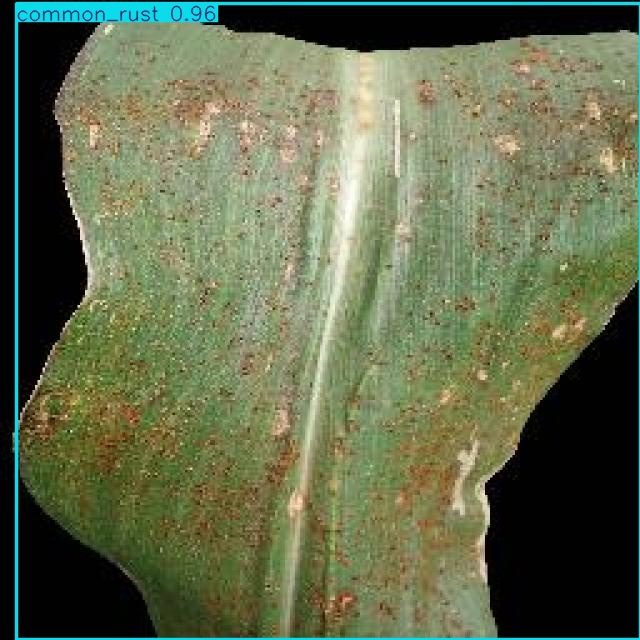

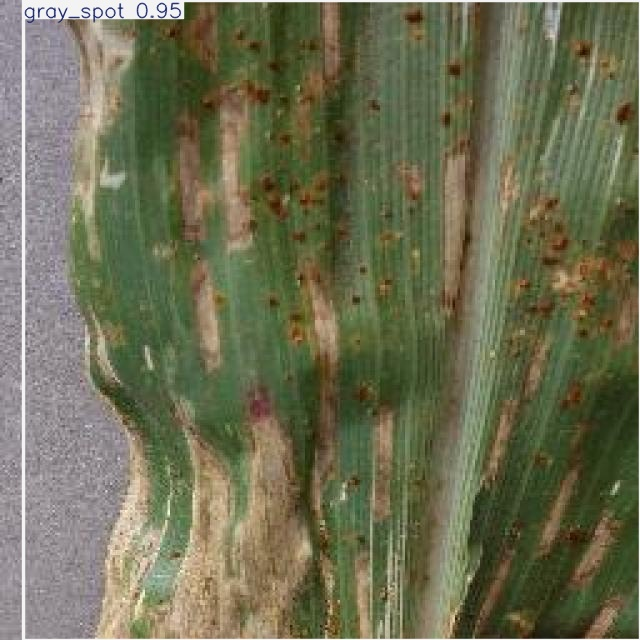

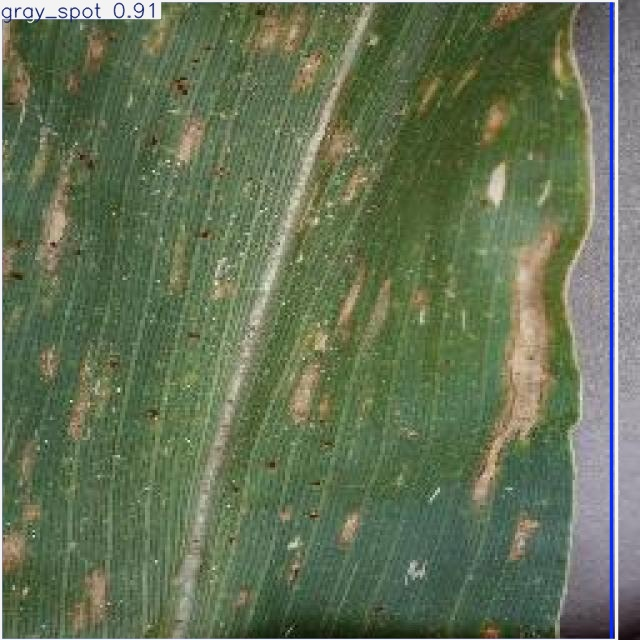

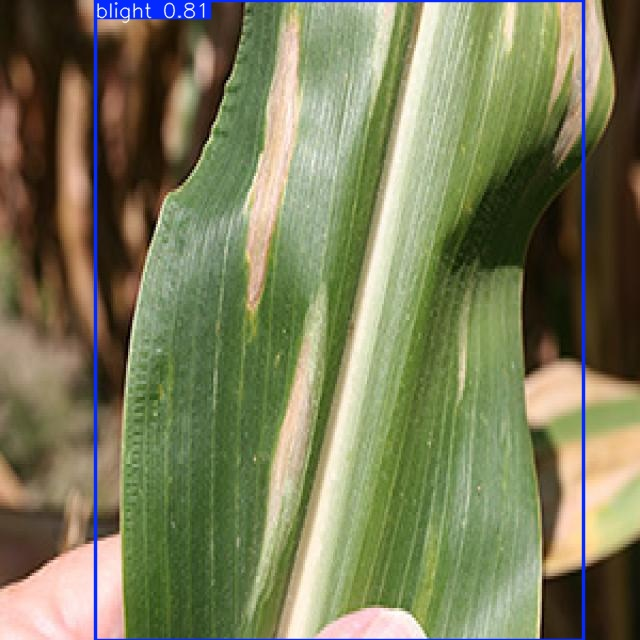

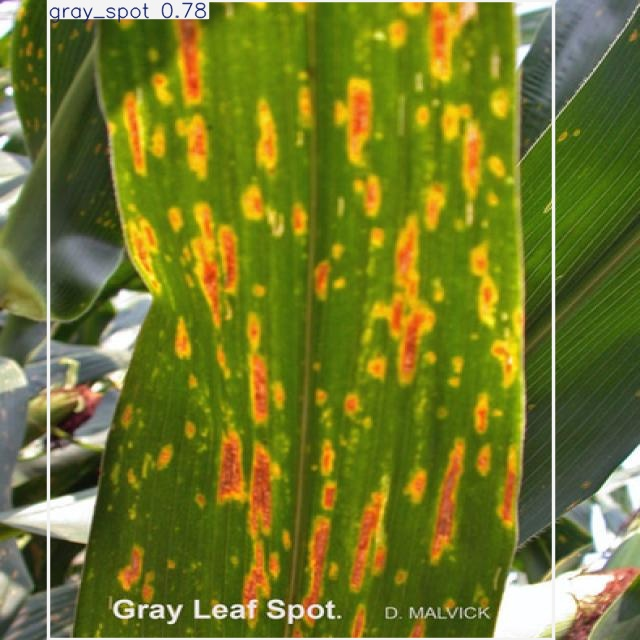

In [11]:
from pathlib import Path
from IPython.display import display, Image as IPImage

result_gaf = gaf_model.predict(
    source=f"{dataset.location}/test/images",
    conf=0.25,
    save=True,
    name="gafnet_test_preds",
    verbose=False
)

pred_dir = Path("/kaggle/working/runs/detect/gafnet_test_preds")
imgs = [p for p in pred_dir.rglob("*") if p.suffix.lower() in [".jpg", ".jpeg", ".png"]]
for img in imgs[:5]:
    display(IPImage(filename=str(img)))

---
## 📊 Step 9 — Training Curves: Baseline vs GAF-Net
Reads `results.csv` generated by YOLO automatically for each run.

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ── Load training CSVs ──────────────────────────────────────────────────────
baseline_csv = "/kaggle/working/runs/detect/baseline/results.csv"
gafnet_csv   = "/kaggle/working/runs/detect/gafnet_corn/results.csv"

df_base = pd.read_csv(baseline_csv)
df_gaf  = pd.read_csv(gafnet_csv)

# Strip whitespace from column names (YOLO sometimes adds spaces)
df_base.columns = df_base.columns.str.strip()
df_gaf.columns  = df_gaf.columns.str.strip()

print("Baseline columns :", df_base.columns.tolist())
print("GAF-Net columns  :", df_gaf.columns.tolist())

Baseline columns : ['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2', 'lr/pg3', 'lr/pg4', 'lr/pg5', 'lr/pg6', 'lr/pg7']
GAF-Net columns  : ['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


### 9a — Loss Curves (Train & Val)

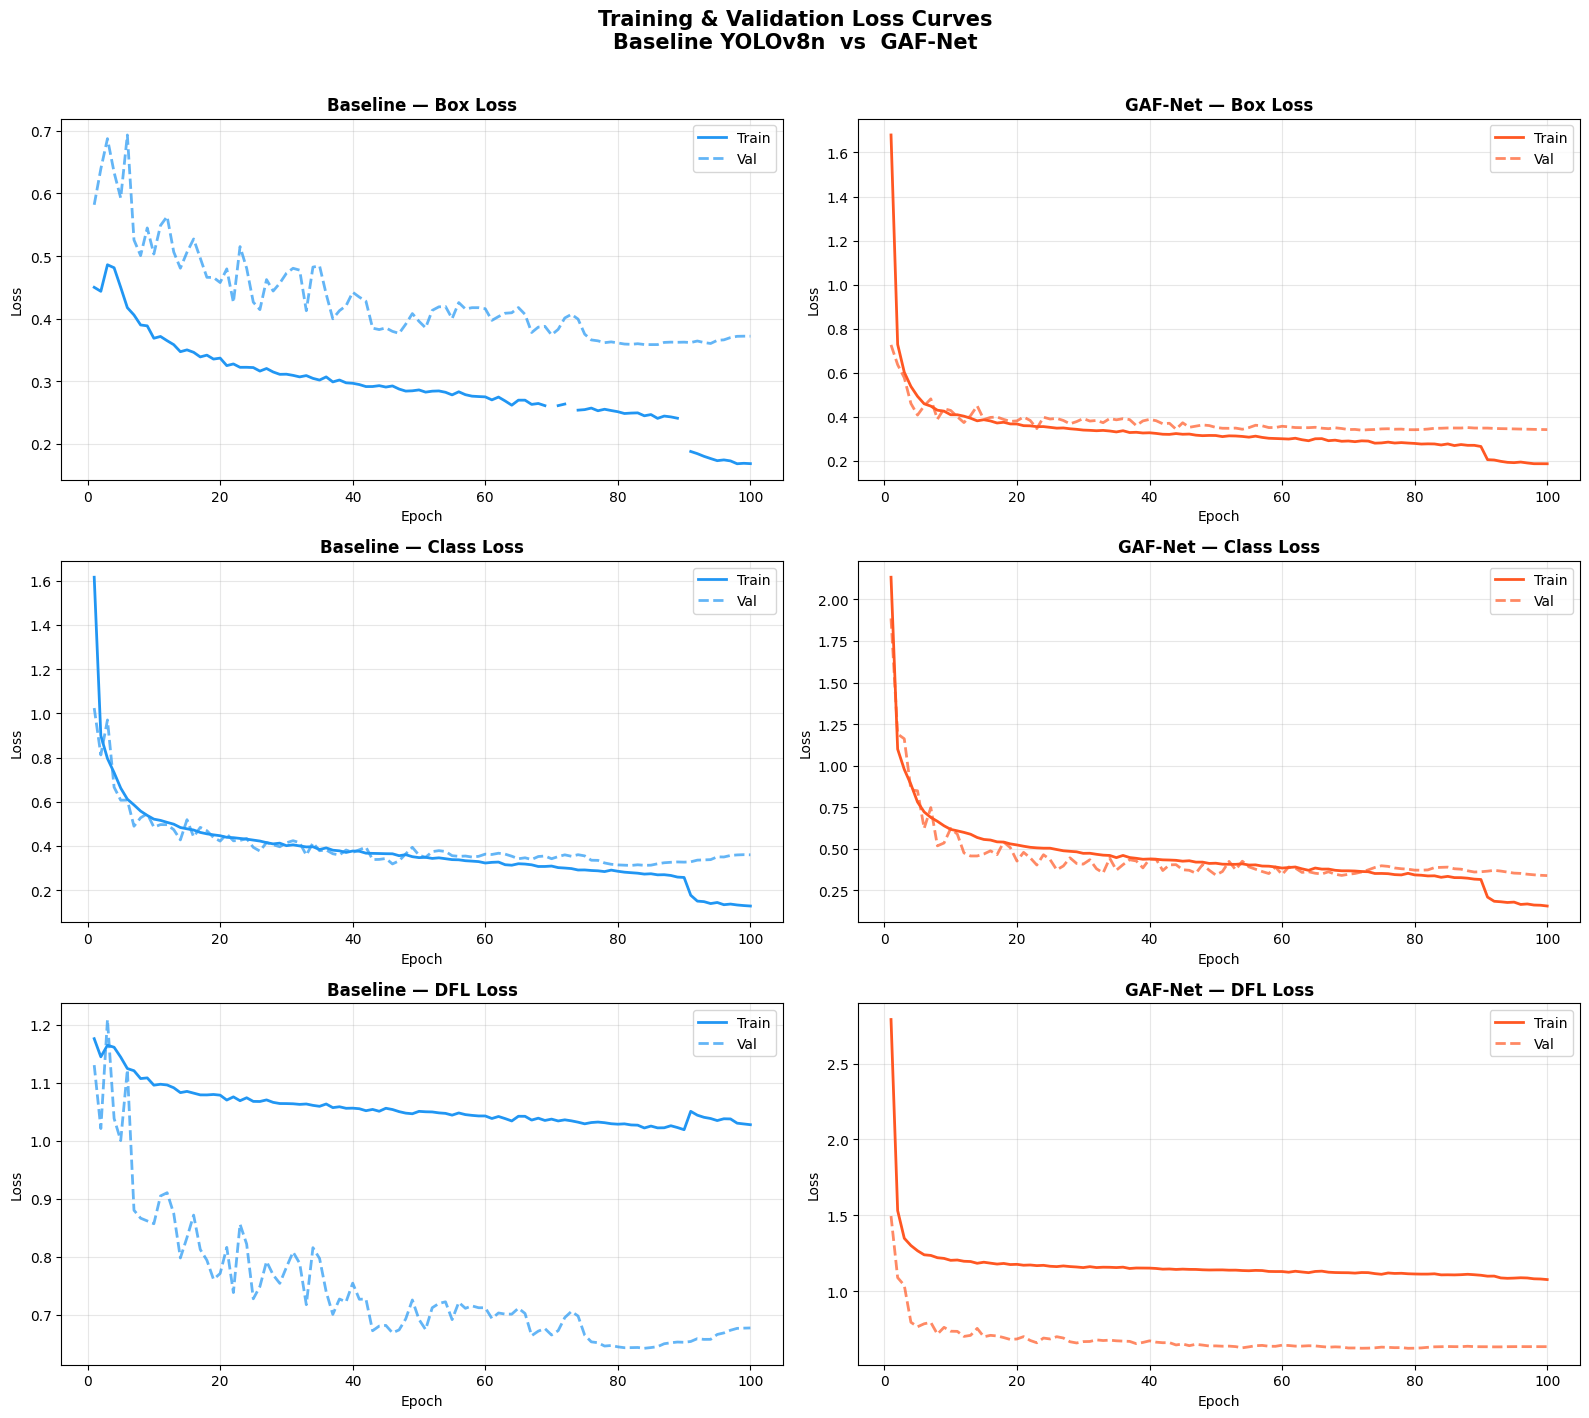

✅ Saved → /kaggle/working/saved_checkpoints/plot_loss_curves.png


In [13]:
# ── Colour palette ──────────────────────────────────────────────────────────
C_BASE = "#2196F3"   # blue  → Baseline
C_GAF  = "#FF5722"   # deep orange → GAF-Net

loss_pairs = [
    ("train/box_loss", "val/box_loss",  "Box Loss"),
    ("train/cls_loss", "val/cls_loss",  "Class Loss"),
    ("train/dfl_loss", "val/dfl_loss",  "DFL Loss"),
]

fig, axes = plt.subplots(3, 2, figsize=(16, 14))
fig.suptitle("Training & Validation Loss Curves\nBaseline YOLOv8n  vs  GAF-Net",
             fontsize=15, fontweight="bold", y=1.01)

for row, (train_col, val_col, title) in enumerate(loss_pairs):
    for col, (df, label, color) in enumerate(
        [(df_base, "Baseline", C_BASE), (df_gaf, "GAF-Net", C_GAF)]
    ):
        ax = axes[row][col]
        epochs = df["epoch"]
        ax.plot(epochs, df[train_col], color=color, lw=2, label="Train")
        ax.plot(epochs, df[val_col],   color=color, lw=2, ls="--", alpha=0.7, label="Val")
        ax.set_title(f"{label} — {title}", fontweight="bold")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")
        ax.legend()
        ax.grid(True, alpha=0.3)

plt.tight_layout()
loss_path = "/kaggle/working/saved_checkpoints/plot_loss_curves.png"
plt.savefig(loss_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"✅ Saved → {loss_path}")

### 9b — mAP Curves (mAP@0.5 and mAP@0.5:0.95)

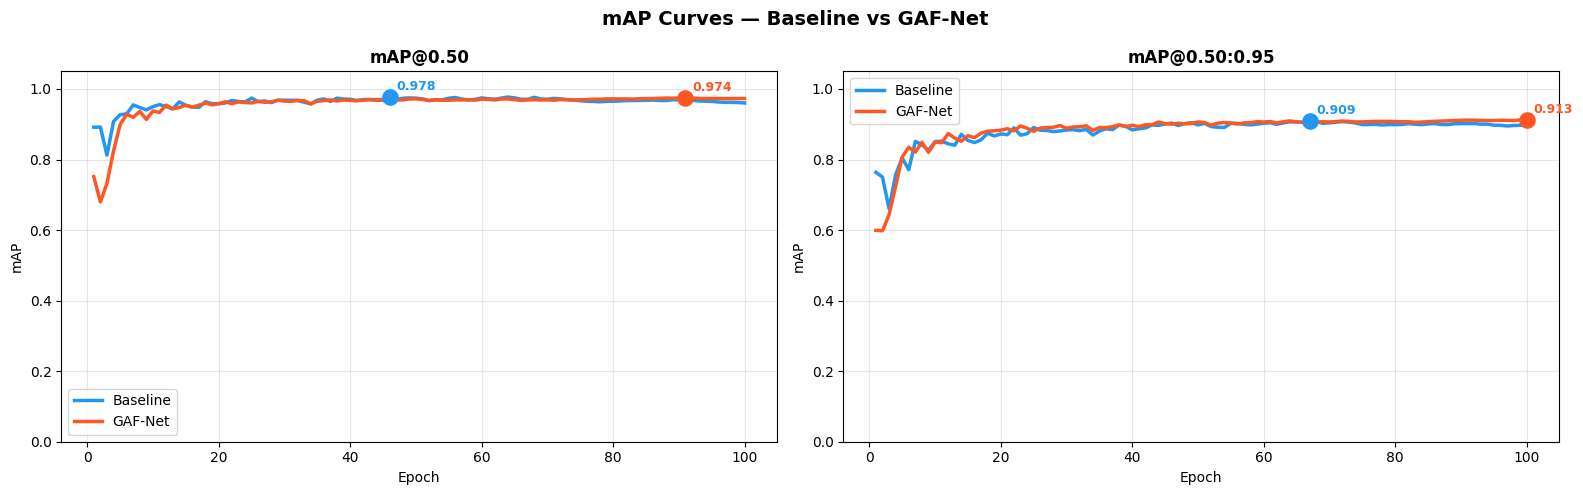

✅ Saved → /kaggle/working/saved_checkpoints/plot_map_curves.png


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle("mAP Curves — Baseline vs GAF-Net", fontsize=14, fontweight="bold")

map_metrics = [
    ("metrics/mAP50(B)",    "mAP@0.50"),
    ("metrics/mAP50-95(B)", "mAP@0.50:0.95"),
]

for ax, (col, title) in zip(axes, map_metrics):
    ax.plot(df_base["epoch"], df_base[col], color=C_BASE, lw=2.5, label="Baseline")
    ax.plot(df_gaf["epoch"],  df_gaf[col],  color=C_GAF,  lw=2.5, label="GAF-Net")

    # Mark best epoch for each
    for df, color, label in [(df_base, C_BASE, "Baseline"), (df_gaf, C_GAF, "GAF-Net")]:
        best_idx = df[col].idxmax()
        best_ep  = df.loc[best_idx, "epoch"]
        best_val = df.loc[best_idx, col]
        ax.scatter(best_ep, best_val, color=color, s=120, zorder=5)
        ax.annotate(f"{best_val:.3f}",
                    xy=(best_ep, best_val), xytext=(5, 5),
                    textcoords="offset points", fontsize=9, color=color, fontweight="bold")

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("mAP")
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0, 1.05)

plt.tight_layout()
map_path = "/kaggle/working/saved_checkpoints/plot_map_curves.png"
plt.savefig(map_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"✅ Saved → {map_path}")

### 9c — Precision & Recall Curves

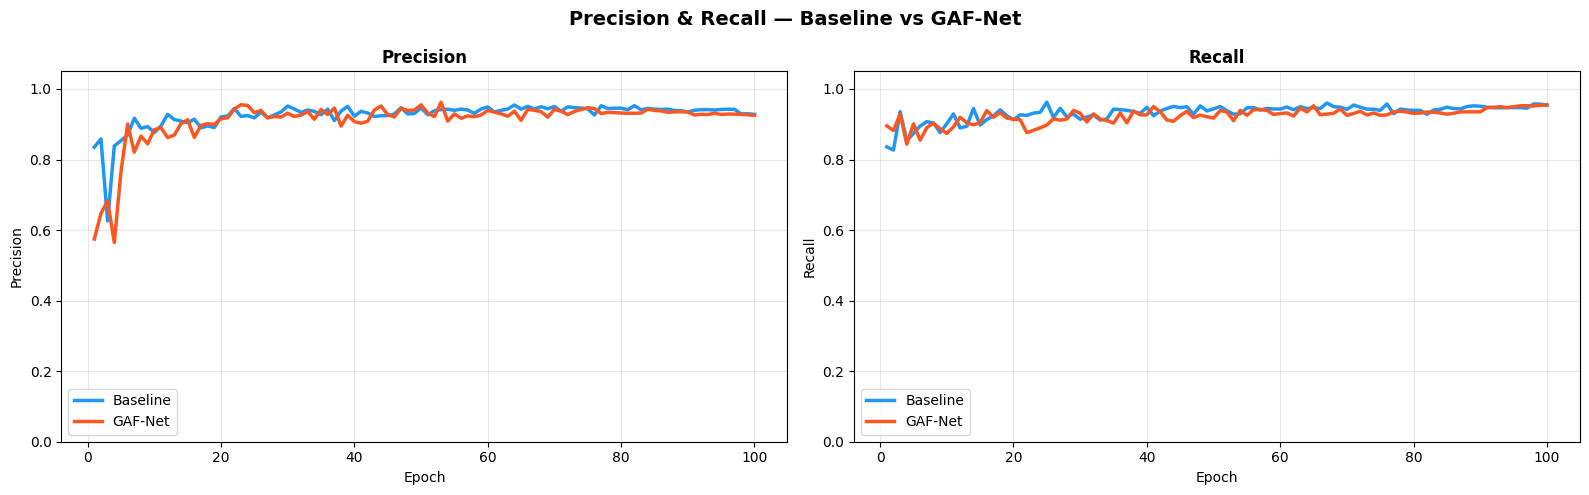

✅ Saved → /kaggle/working/saved_checkpoints/plot_precision_recall.png


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle("Precision & Recall — Baseline vs GAF-Net", fontsize=14, fontweight="bold")

pr_metrics = [
    ("metrics/precision(B)", "Precision"),
    ("metrics/recall(B)",    "Recall"),
]

for ax, (col, title) in zip(axes, pr_metrics):
    ax.plot(df_base["epoch"], df_base[col], color=C_BASE, lw=2.5, label="Baseline")
    ax.plot(df_gaf["epoch"],  df_gaf[col],  color=C_GAF,  lw=2.5, label="GAF-Net")
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0, 1.05)

plt.tight_layout()
pr_path = "/kaggle/working/saved_checkpoints/plot_precision_recall.png"
plt.savefig(pr_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"✅ Saved → {pr_path}")

### 9d — All Metrics on One Dashboard

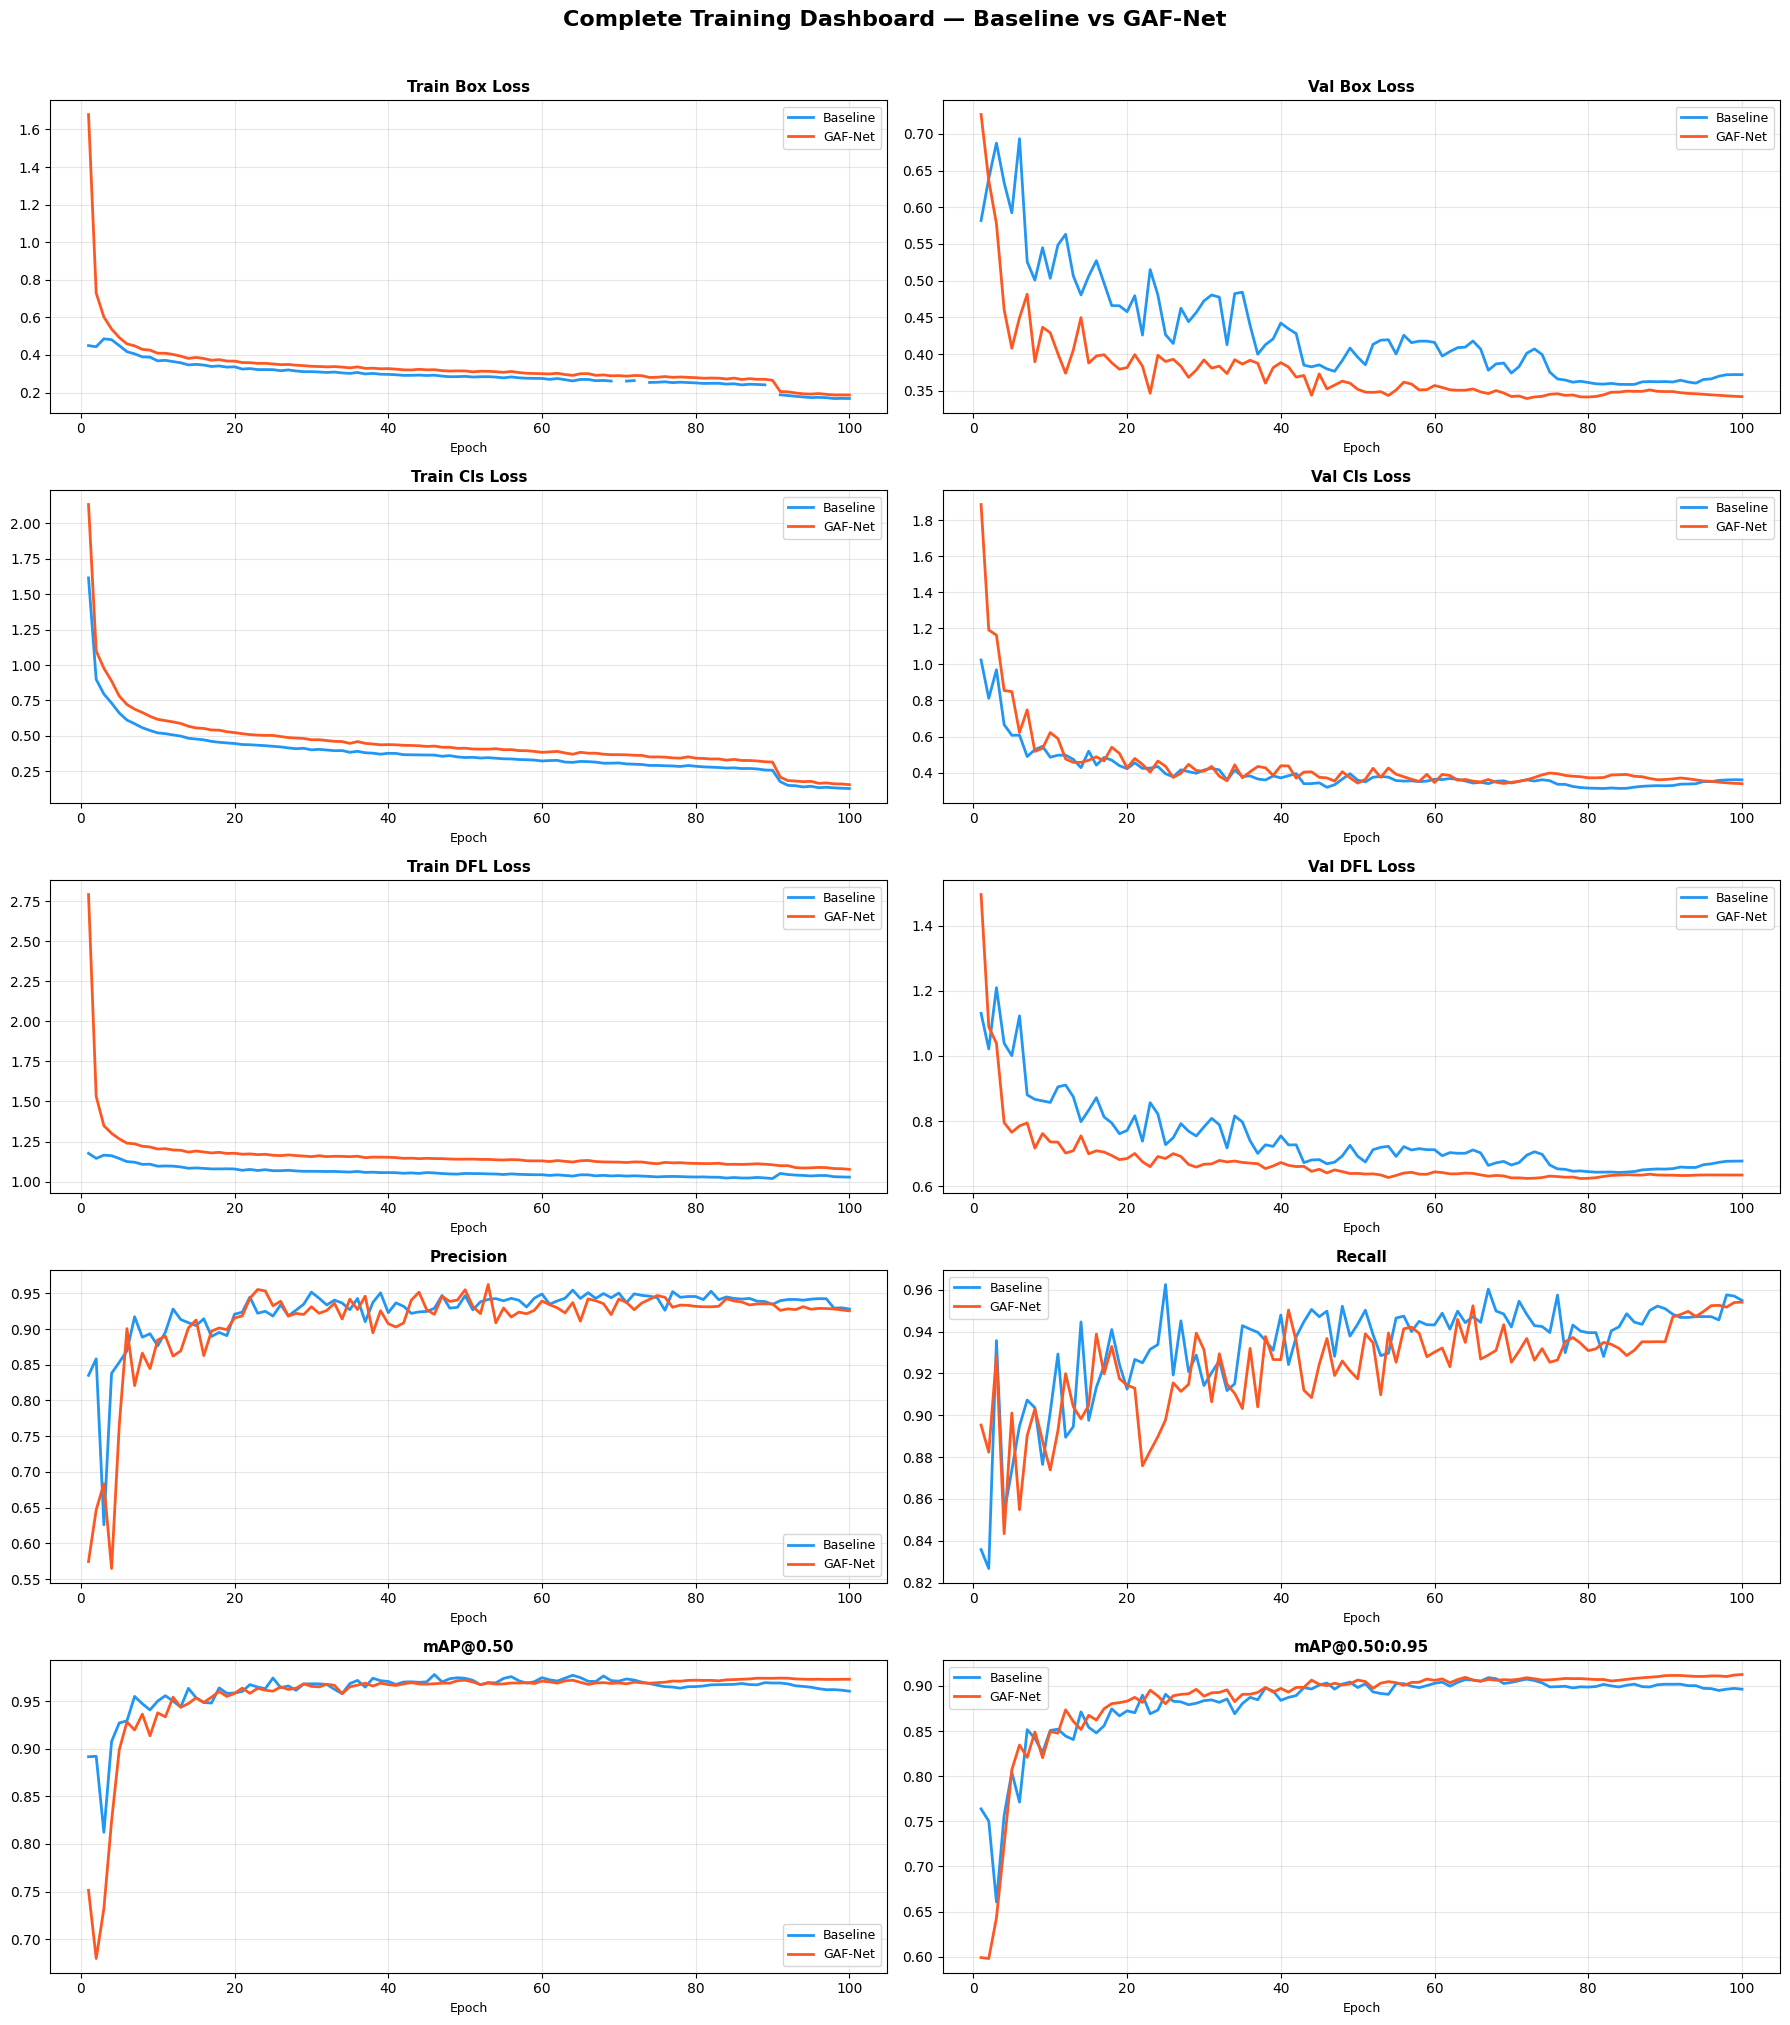

✅ Saved → /kaggle/working/saved_checkpoints/plot_full_dashboard.png


In [16]:
metrics_to_plot = [
    ("train/box_loss",         "Train Box Loss"),
    ("val/box_loss",           "Val Box Loss"),
    ("train/cls_loss",         "Train Cls Loss"),
    ("val/cls_loss",           "Val Cls Loss"),
    ("train/dfl_loss",         "Train DFL Loss"),
    ("val/dfl_loss",           "Val DFL Loss"),
    ("metrics/precision(B)",   "Precision"),
    ("metrics/recall(B)",      "Recall"),
    ("metrics/mAP50(B)",       "mAP@0.50"),
    ("metrics/mAP50-95(B)",    "mAP@0.50:0.95"),
]

n_cols = 2
n_rows = (len(metrics_to_plot) + 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
fig.suptitle("Complete Training Dashboard — Baseline vs GAF-Net",
             fontsize=16, fontweight="bold", y=1.01)

axes_flat = axes.flatten()

for idx, (col, title) in enumerate(metrics_to_plot):
    ax = axes_flat[idx]
    ax.plot(df_base["epoch"], df_base[col], color=C_BASE, lw=2, label="Baseline")
    ax.plot(df_gaf["epoch"],  df_gaf[col],  color=C_GAF,  lw=2, label="GAF-Net")
    ax.set_title(title, fontweight="bold", fontsize=11)
    ax.set_xlabel("Epoch", fontsize=9)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

# Hide any unused subplots
for idx in range(len(metrics_to_plot), len(axes_flat)):
    axes_flat[idx].set_visible(False)

plt.tight_layout()
dashboard_path = "/kaggle/working/saved_checkpoints/plot_full_dashboard.png"
plt.savefig(dashboard_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"✅ Saved → {dashboard_path}")

### 9e — Final Metrics Summary Table (Best Epoch)


          FINAL METRICS SUMMARY  (Best Epoch by mAP@0.50)
               Baseline YOLOv8n  GAF-Net (Ours)  Δ (GAF - Base)
Precision                0.9290          0.9262         -0.0029
Recall                   0.9498          0.9470         -0.0027
mAP@0.50                 0.9779          0.9742         -0.0038
mAP@0.50:0.95            0.9033          0.9116          0.0084
Val Box Loss             0.3797          0.3489         -0.0308
Val Cls Loss             0.3188          0.3655          0.0467
Val DFL Loss             0.6687          0.6337         -0.0350


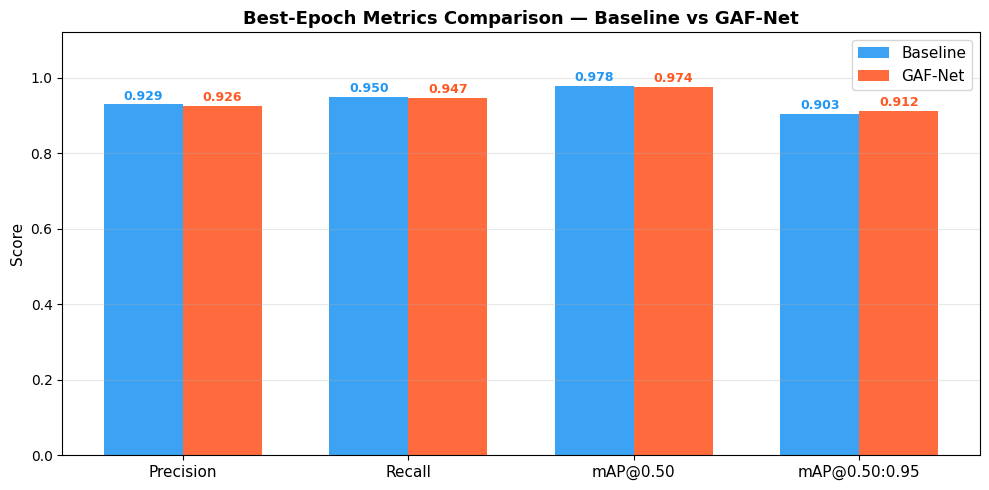

✅ Saved → /kaggle/working/saved_checkpoints/plot_metrics_bar_comparison.png


In [17]:
import pandas as pd

summary_cols = [
    "metrics/precision(B)",
    "metrics/recall(B)",
    "metrics/mAP50(B)",
    "metrics/mAP50-95(B)",
    "val/box_loss",
    "val/cls_loss",
    "val/dfl_loss",
]

# Pick the row with best mAP50 for each model
base_best = df_base.loc[df_base["metrics/mAP50(B)"].idxmax(), summary_cols]
gaf_best  = df_gaf.loc[df_gaf["metrics/mAP50(B)"].idxmax(),  summary_cols]

summary = pd.DataFrame(
    {"Baseline YOLOv8n": base_best, "GAF-Net (Ours)": gaf_best},
)
summary.index = ["Precision", "Recall", "mAP@0.50", "mAP@0.50:0.95",
                 "Val Box Loss", "Val Cls Loss", "Val DFL Loss"]

# Compute delta
summary["Δ (GAF - Base)"] = summary["GAF-Net (Ours)"] - summary["Baseline YOLOv8n"]

print("\n" + "="*65)
print("          FINAL METRICS SUMMARY  (Best Epoch by mAP@0.50)")
print("="*65)
print(summary.round(4).to_string())
print("="*65)

# ── Bar chart comparison ─────────────────────────────────────────────────────
bar_metrics = ["Precision", "Recall", "mAP@0.50", "mAP@0.50:0.95"]
x = range(len(bar_metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar([i - width/2 for i in x],
               summary.loc[bar_metrics, "Baseline YOLOv8n"],
               width, label="Baseline", color=C_BASE, alpha=0.88)
bars2 = ax.bar([i + width/2 for i in x],
               summary.loc[bar_metrics, "GAF-Net (Ours)"],
               width, label="GAF-Net", color=C_GAF, alpha=0.88)

# Value labels on bars
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=9, color=C_BASE, fontweight="bold")
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=9, color=C_GAF, fontweight="bold")

ax.set_xticks(list(x))
ax.set_xticklabels(bar_metrics, fontsize=11)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Score", fontsize=11)
ax.set_title("Best-Epoch Metrics Comparison — Baseline vs GAF-Net",
             fontsize=13, fontweight="bold")
ax.legend(fontsize=11)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
bar_path = "/kaggle/working/saved_checkpoints/plot_metrics_bar_comparison.png"
plt.savefig(bar_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"✅ Saved → {bar_path}")

### 9f — YOLO Built-in Confusion Matrix & PR Curve (from saved PNGs)


───────────────────────────────────────────────────────
  Baseline — Confusion Matrix
───────────────────────────────────────────────────────


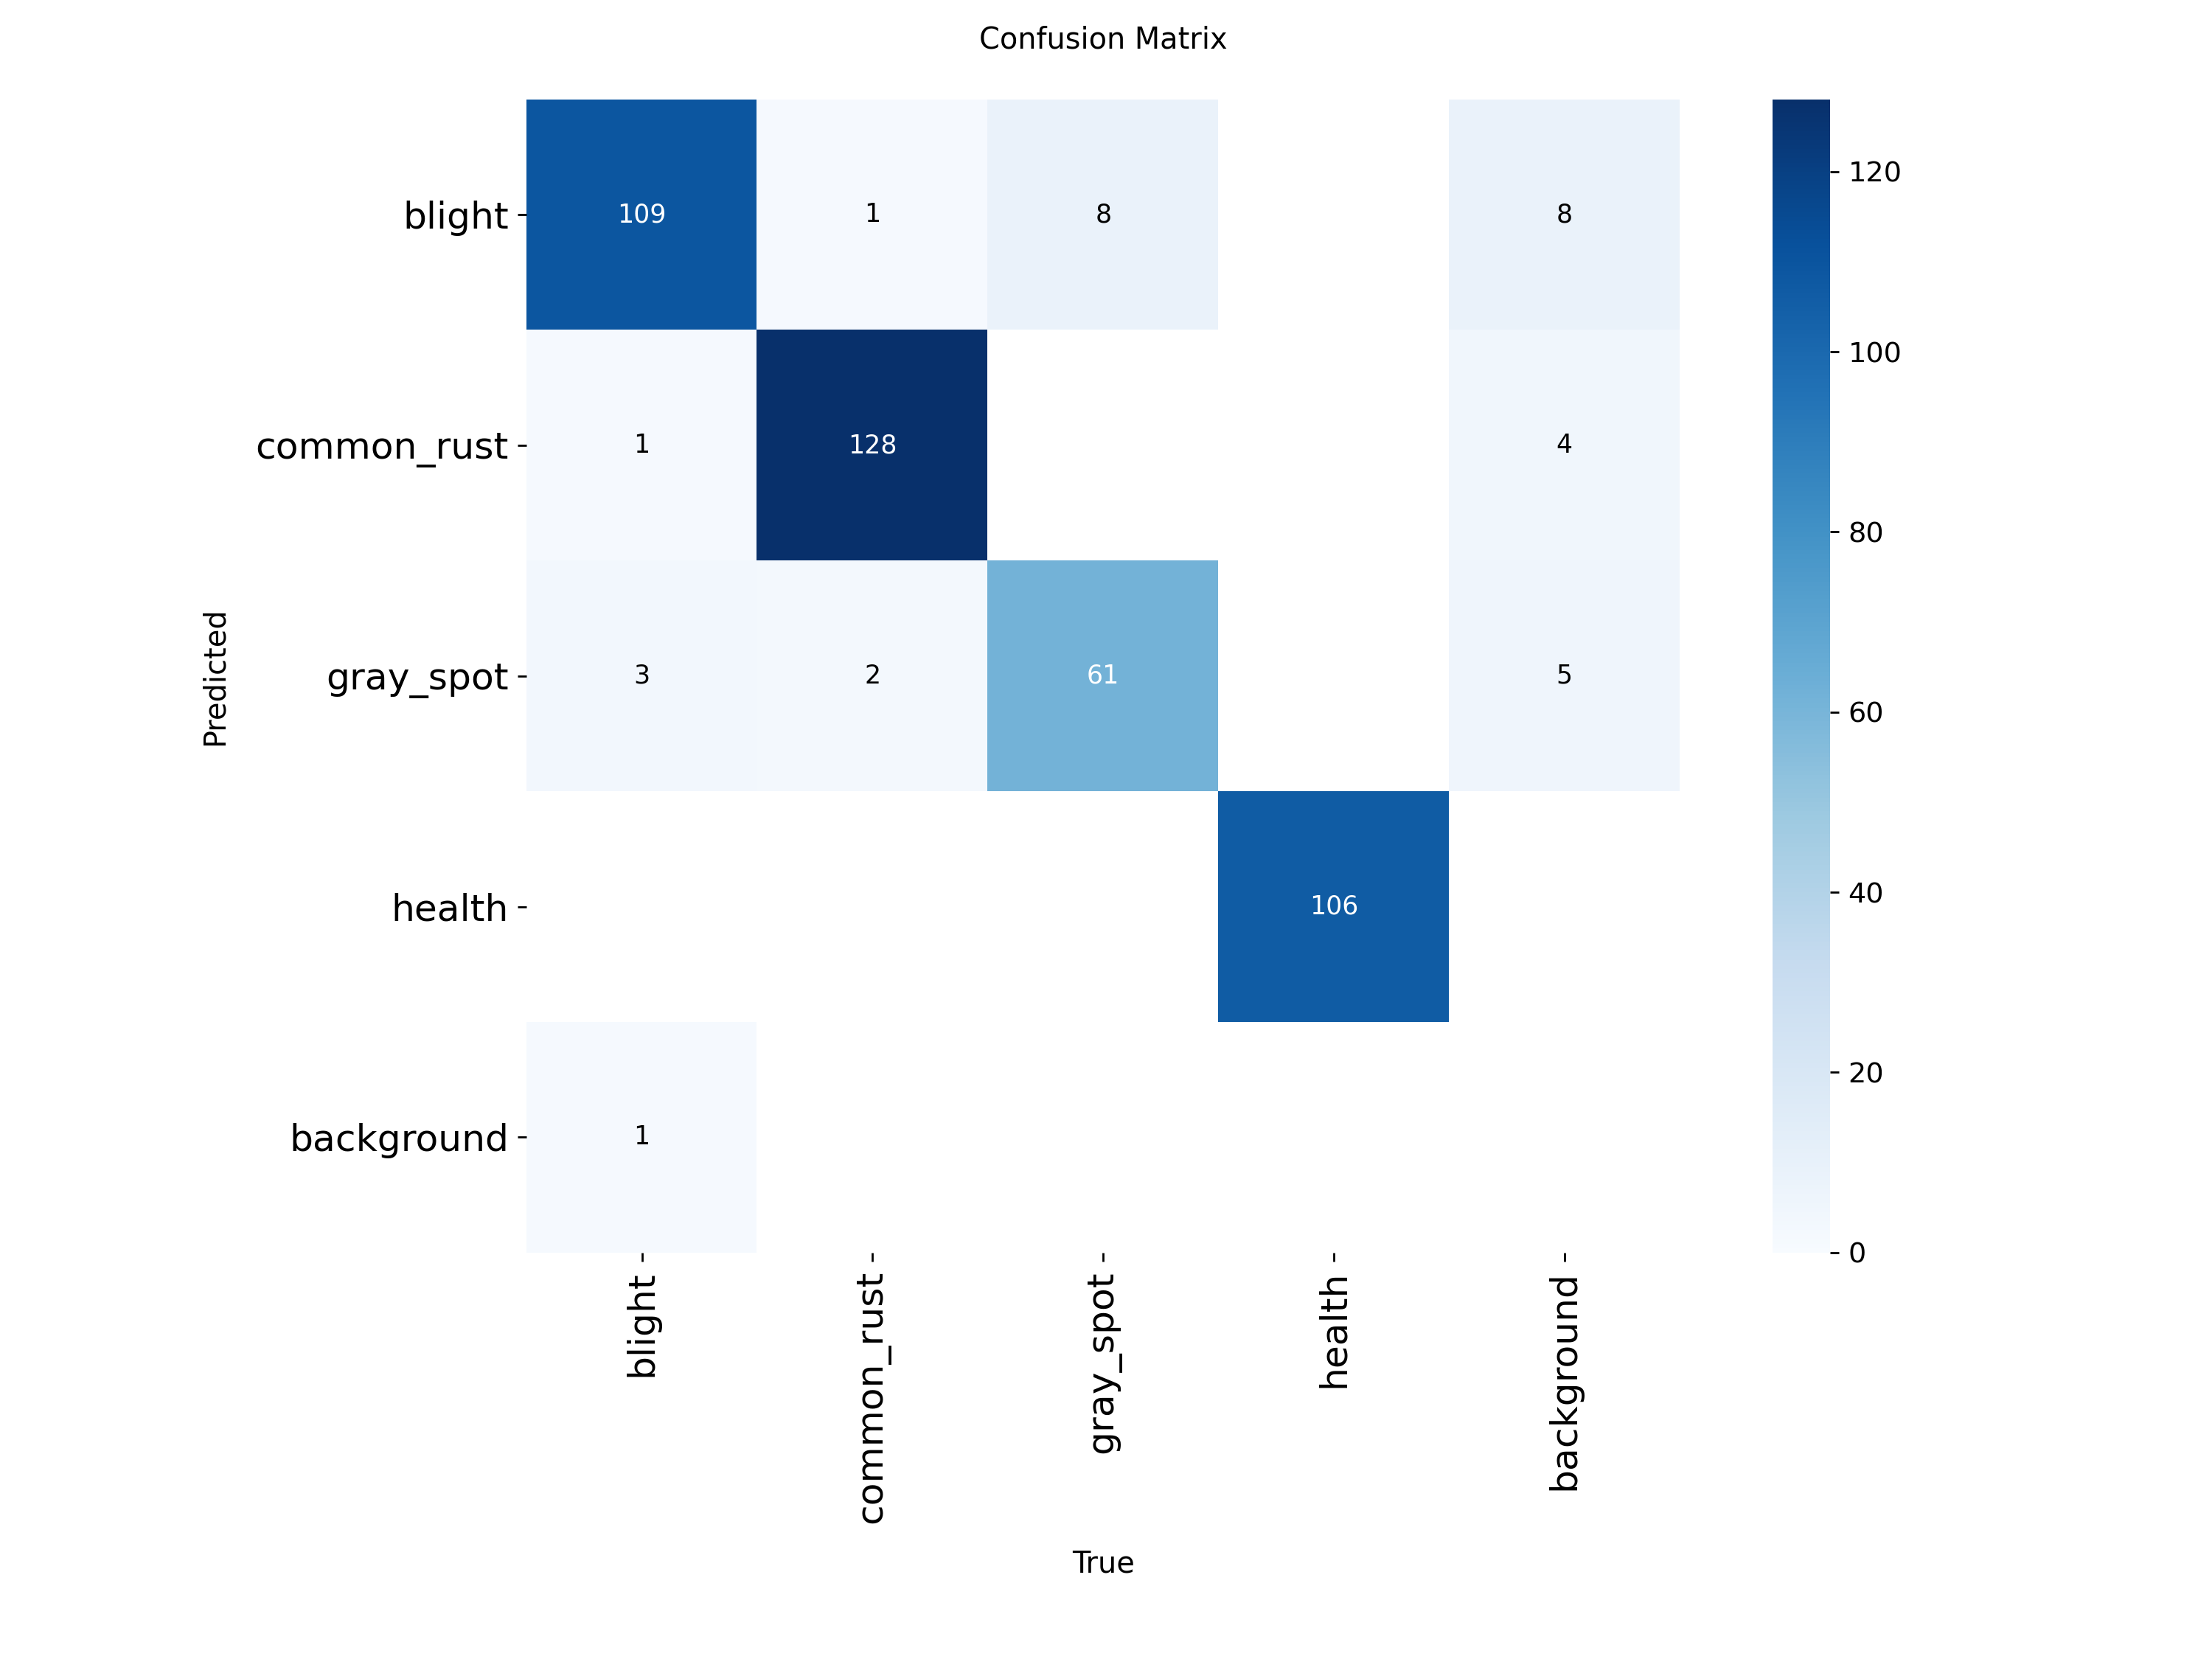


───────────────────────────────────────────────────────
  Baseline — Confusion Matrix (Normalised)
───────────────────────────────────────────────────────


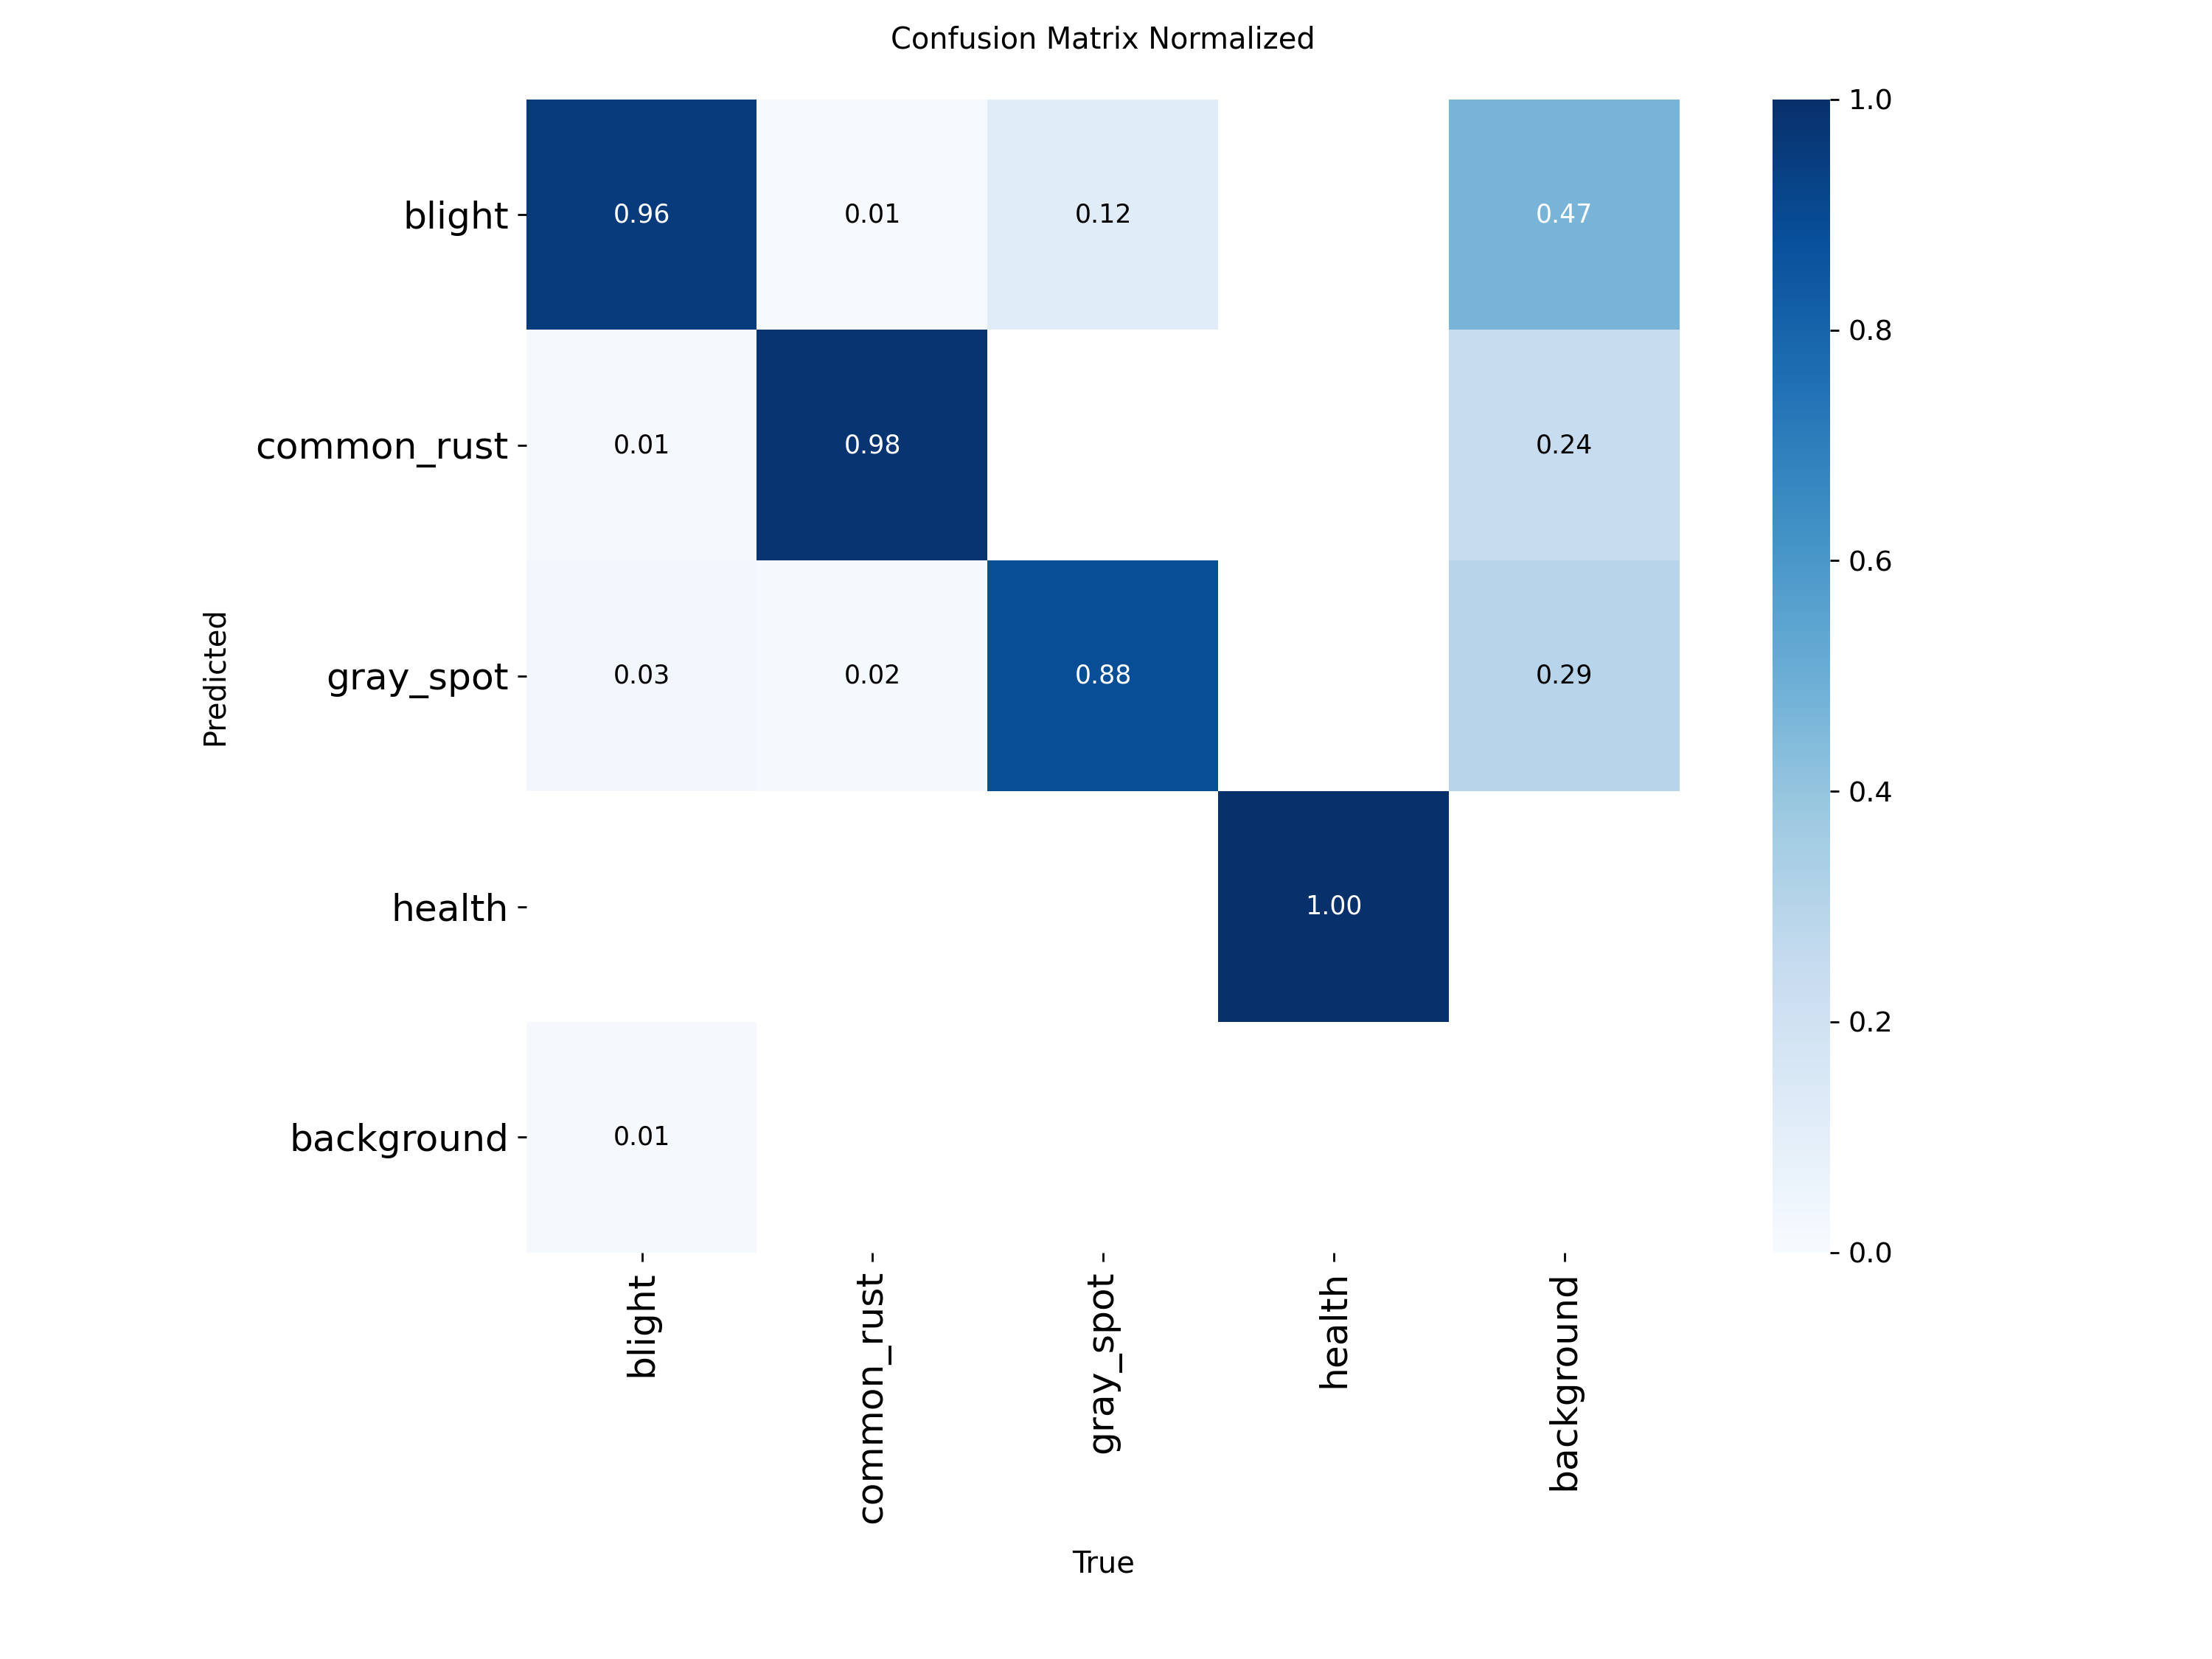

⚠️  Not found: /kaggle/working/runs/detect/baseline/PR_curve.png
⚠️  Not found: /kaggle/working/runs/detect/baseline/F1_curve.png

───────────────────────────────────────────────────────
  GAF-Net — Confusion Matrix
───────────────────────────────────────────────────────


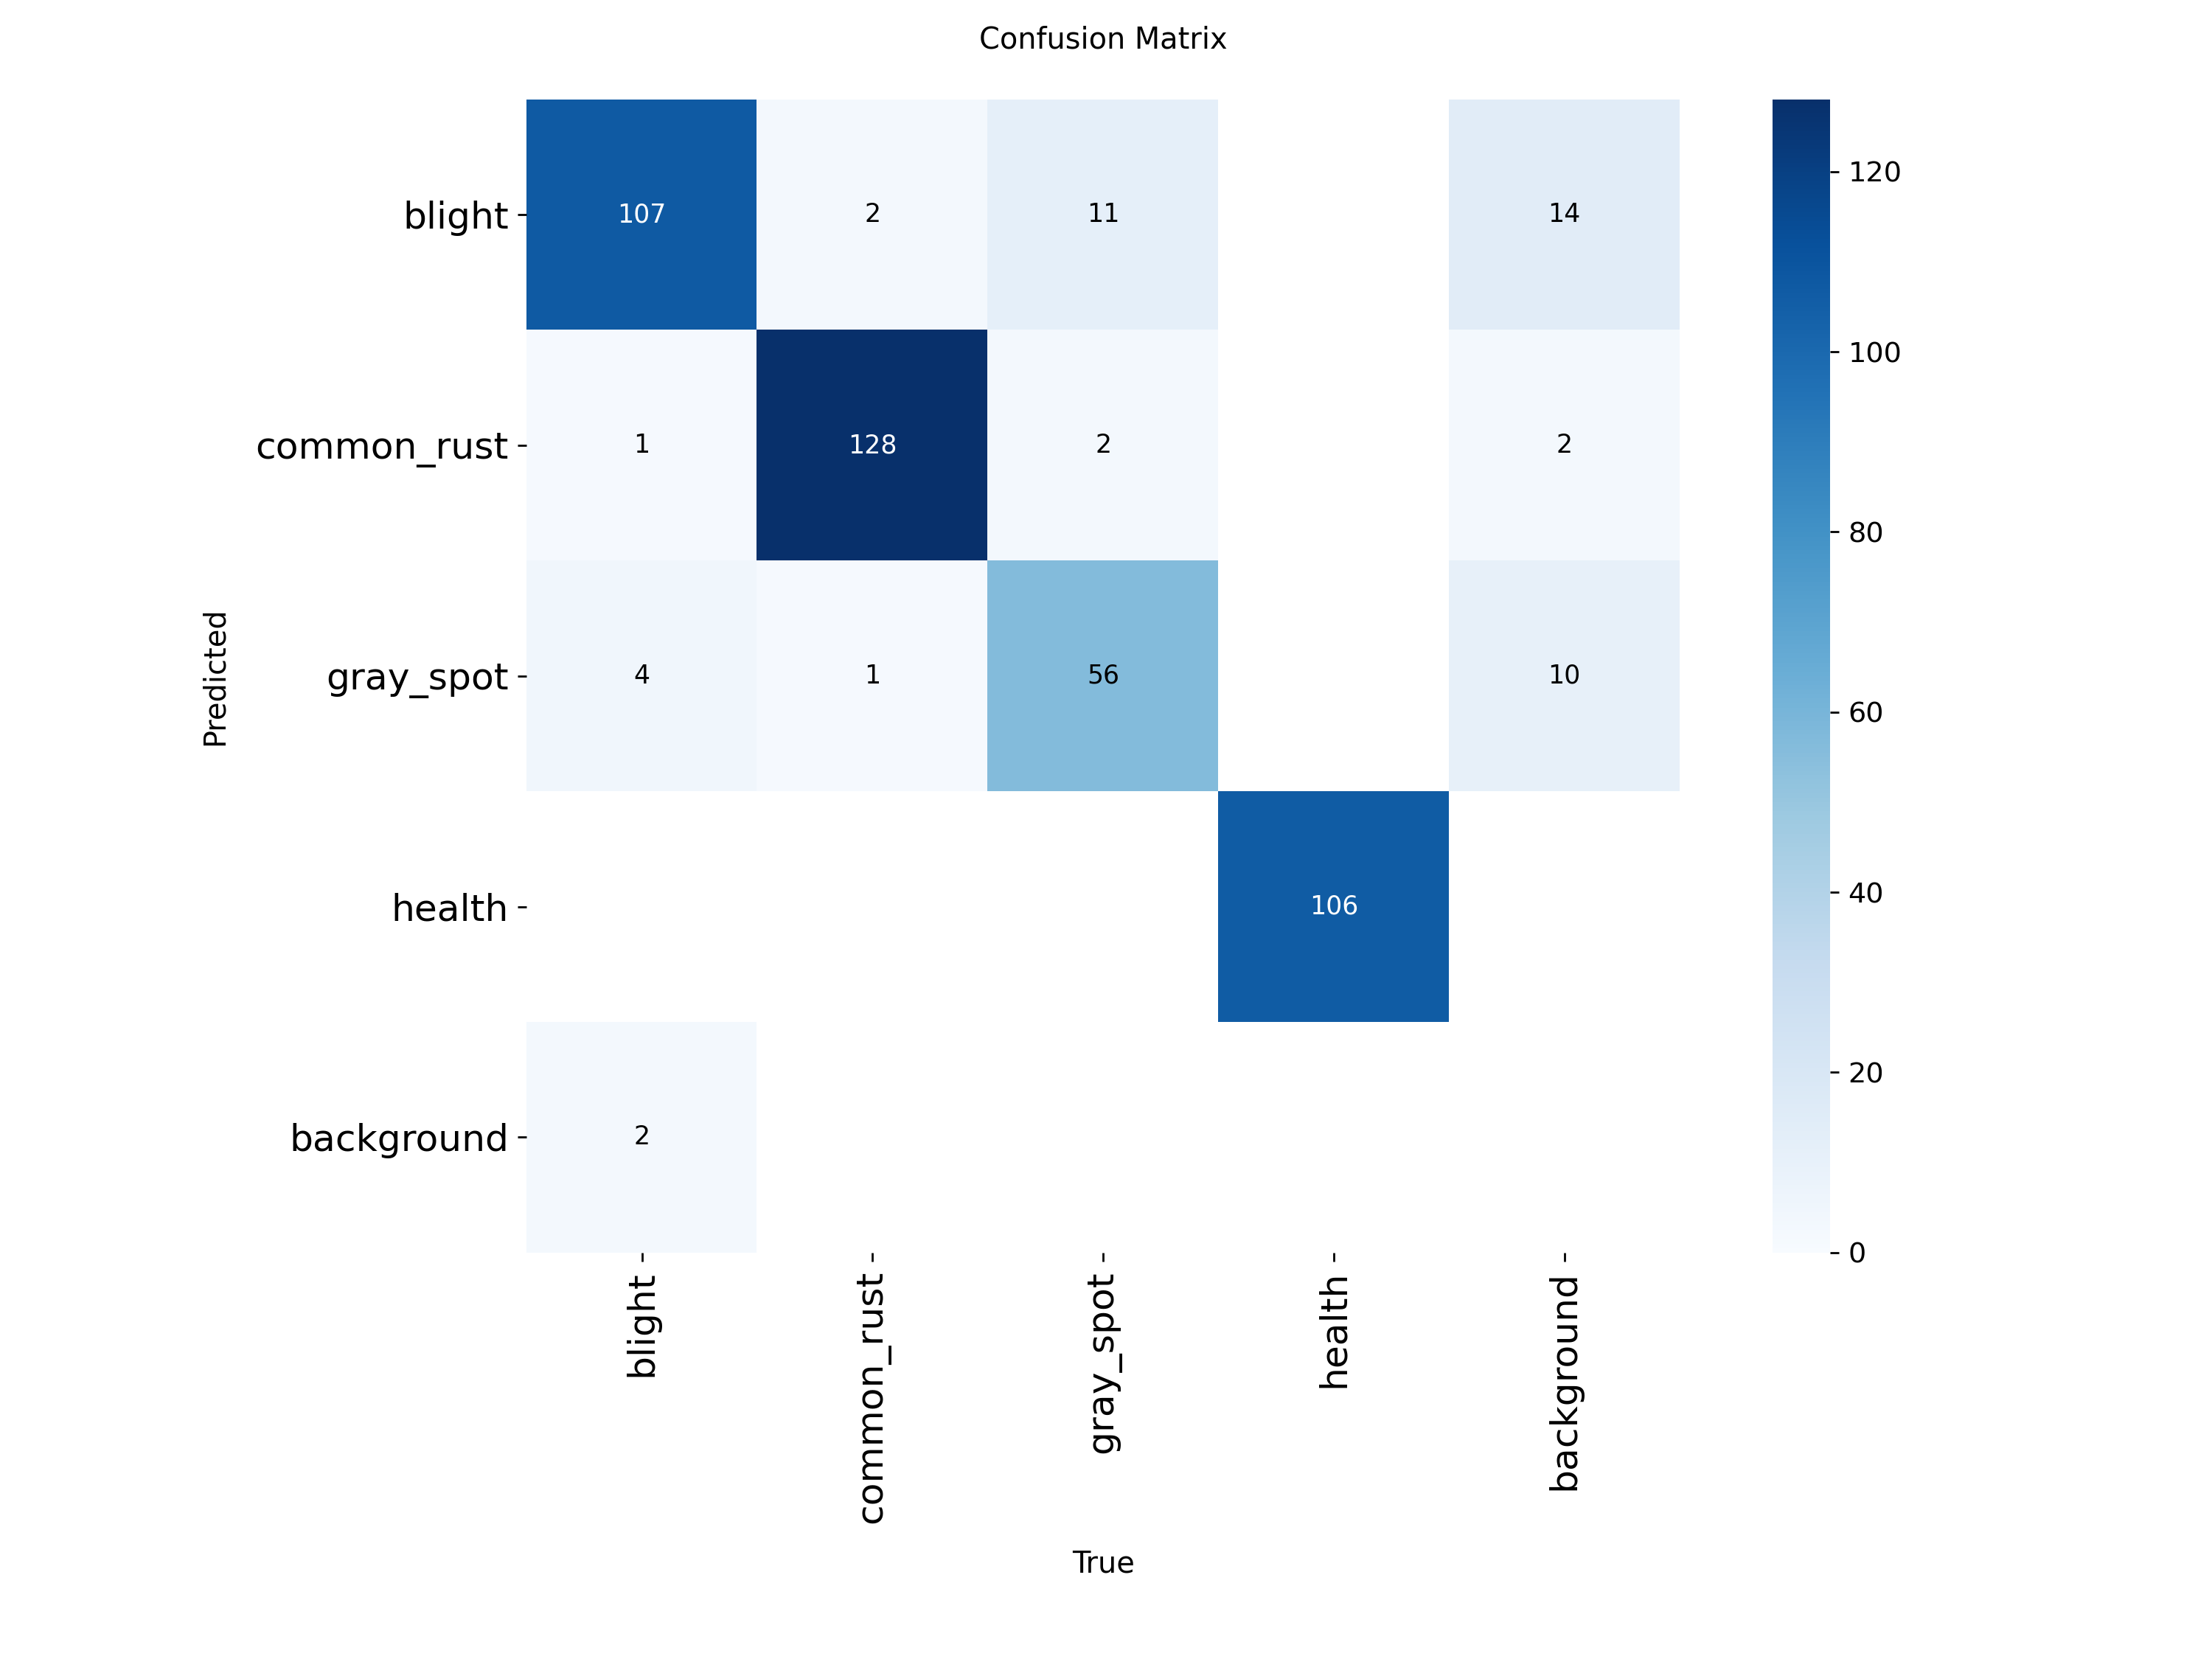


───────────────────────────────────────────────────────
  GAF-Net — Confusion Matrix (Normalised)
───────────────────────────────────────────────────────


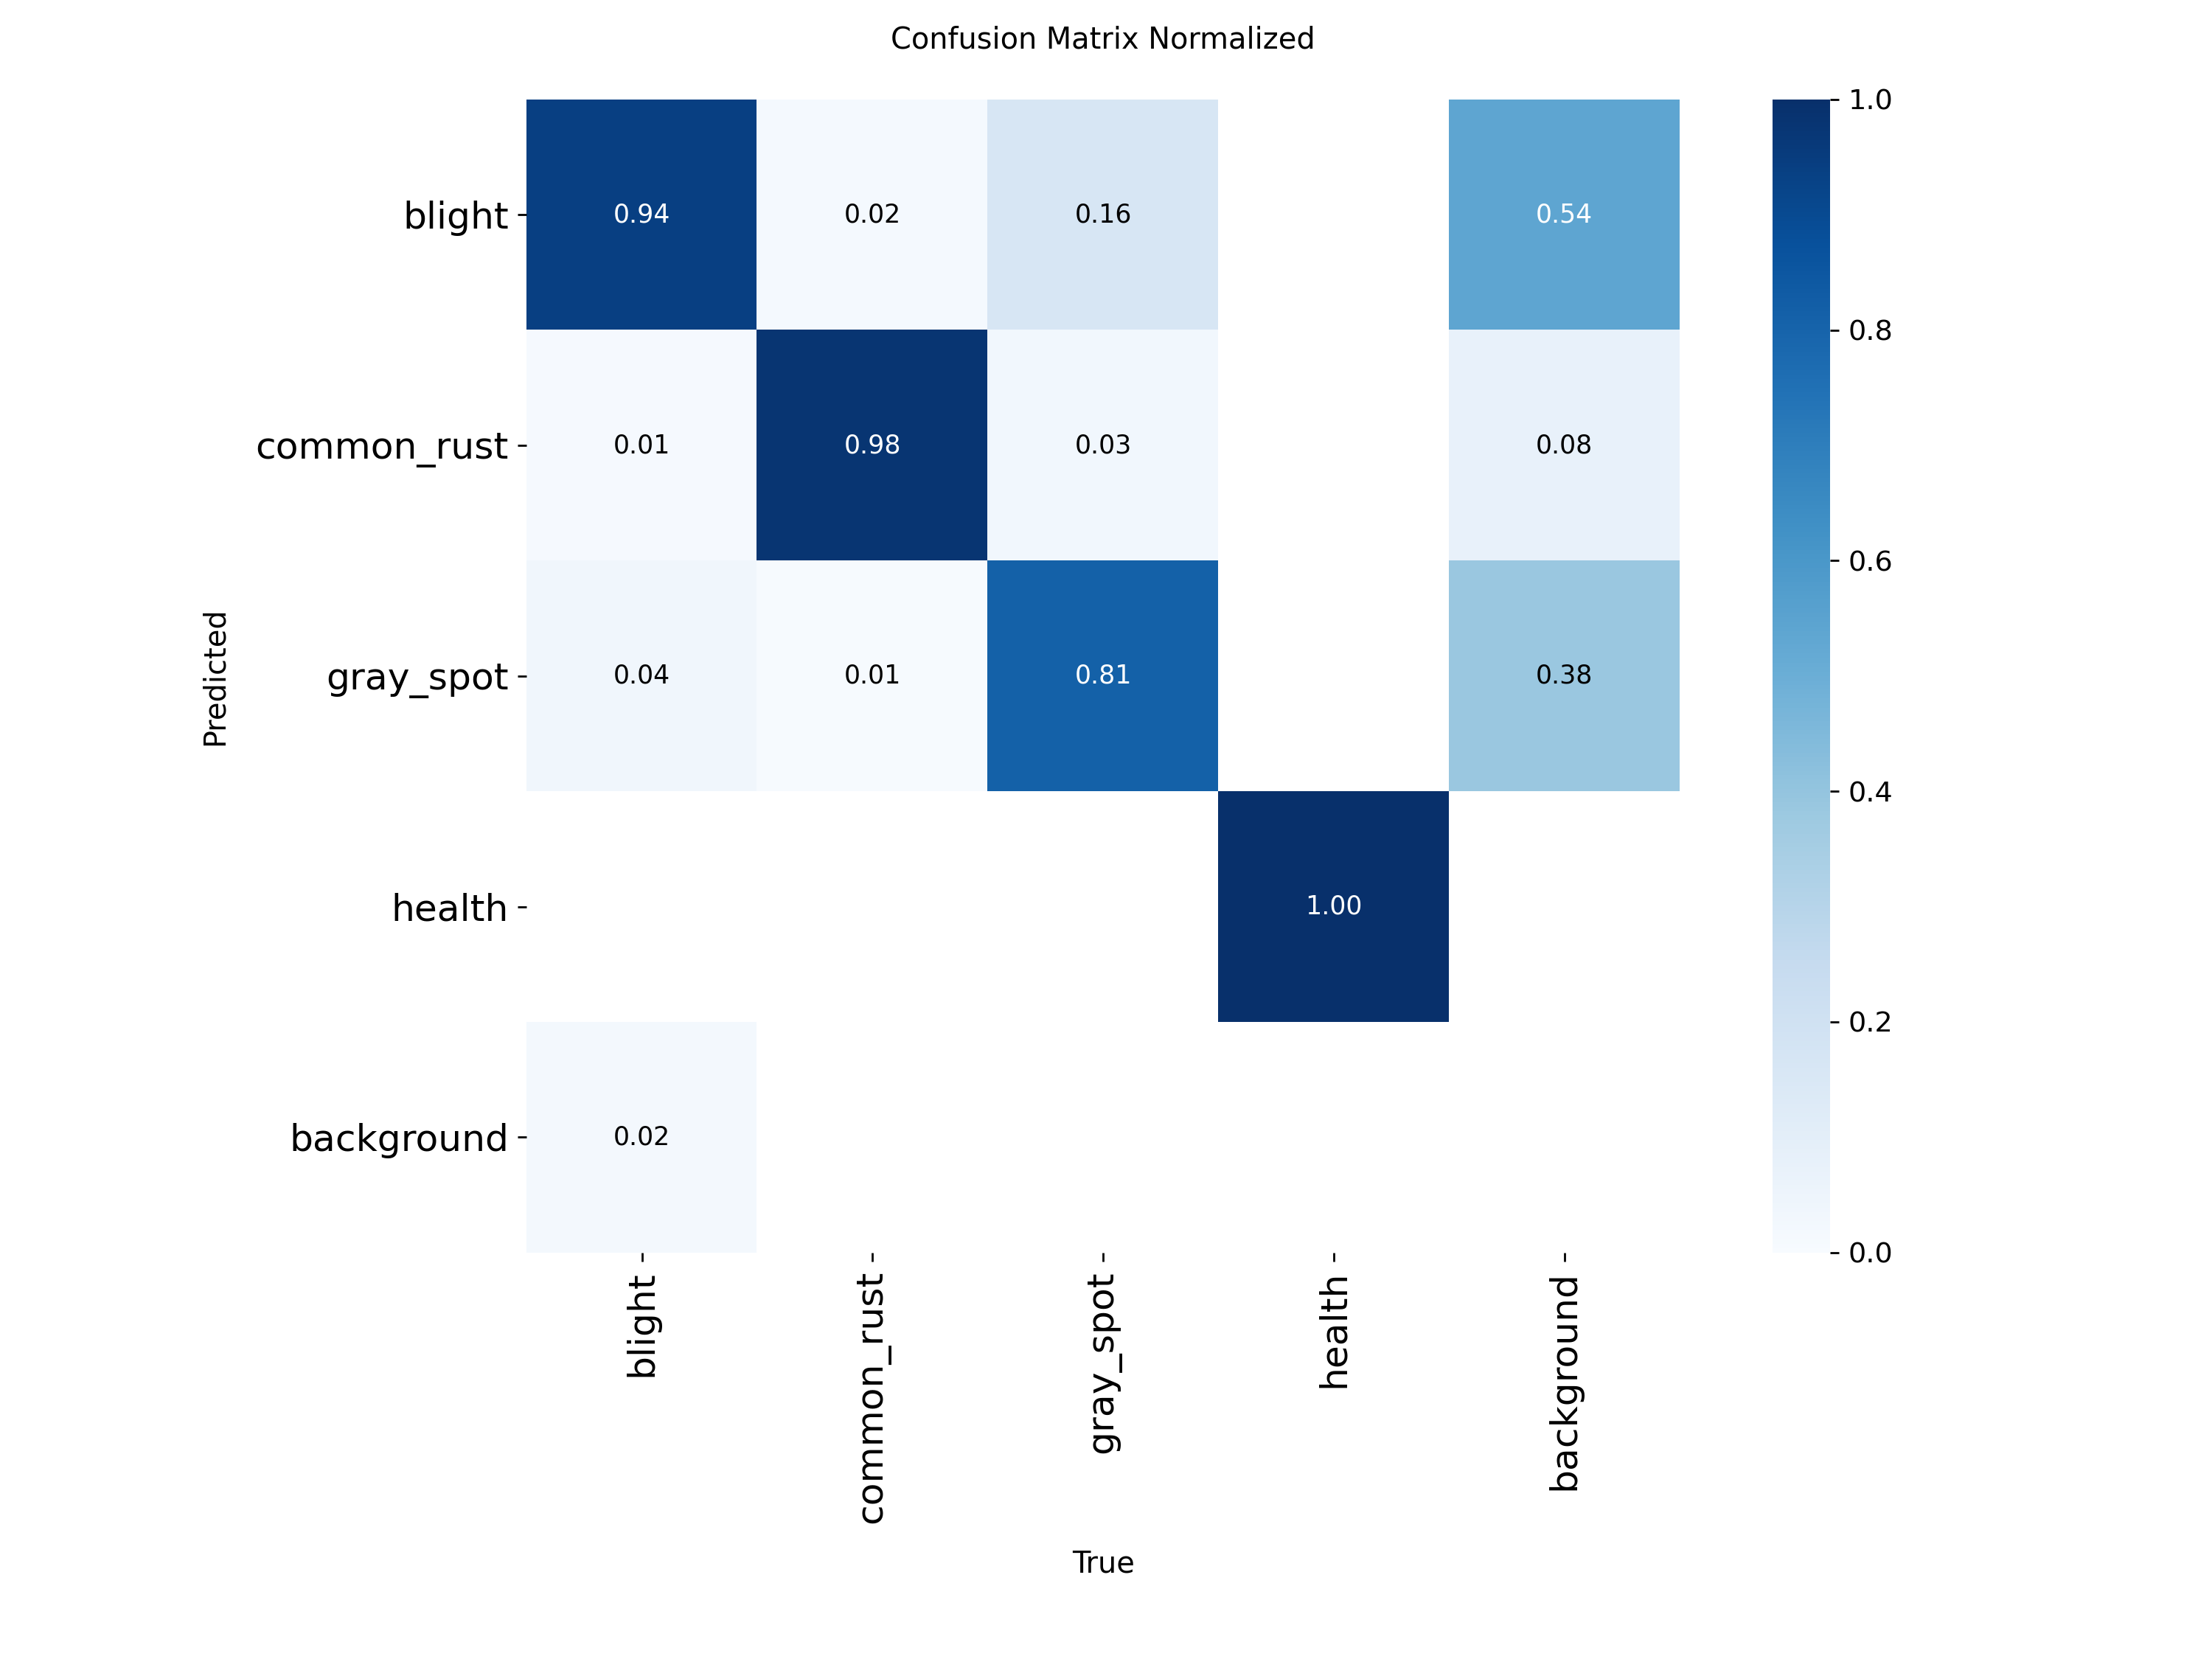

⚠️  Not found: /kaggle/working/runs/detect/gafnet_corn/PR_curve.png
⚠️  Not found: /kaggle/working/runs/detect/gafnet_corn/F1_curve.png


In [18]:
from IPython.display import display, Image as IPImage
from pathlib import Path

# YOLO saves these automatically in the run folder
builtin_plots = [
    ("/kaggle/working/runs/detect/baseline/confusion_matrix.png",          "Baseline — Confusion Matrix"),
    ("/kaggle/working/runs/detect/baseline/confusion_matrix_normalized.png","Baseline — Confusion Matrix (Normalised)"),
    ("/kaggle/working/runs/detect/baseline/PR_curve.png",                   "Baseline — PR Curve"),
    ("/kaggle/working/runs/detect/baseline/F1_curve.png",                   "Baseline — F1 Curve"),
    ("/kaggle/working/runs/detect/gafnet_corn/confusion_matrix.png",        "GAF-Net — Confusion Matrix"),
    ("/kaggle/working/runs/detect/gafnet_corn/confusion_matrix_normalized.png","GAF-Net — Confusion Matrix (Normalised)"),
    ("/kaggle/working/runs/detect/gafnet_corn/PR_curve.png",                "GAF-Net — PR Curve"),
    ("/kaggle/working/runs/detect/gafnet_corn/F1_curve.png",                "GAF-Net — F1 Curve"),
]

for fpath, title in builtin_plots:
    p = Path(fpath)
    if p.exists():
        print(f"\n{'─'*55}")
        print(f"  {title}")
        print(f"{'─'*55}")
        display(IPImage(filename=fpath, width=700))
    else:
        print(f"⚠️  Not found: {fpath}")

### 9g — Per-Class mAP Comparison (from val metrics)

Ultralytics 8.4.42 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1548.5±716.5 MB/s, size: 51.0 KB)
val: Scanning /kaggle/working/Corn-Leaf-Disease-17/test/labels.cache... 417 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 417/417 145.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 6.2it/s 4.3s0.1s
                   all        417        419      0.971      0.964      0.983      0.904
Speed: 1.4ms preprocess, 3.8ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to /kaggle/working/runs/detect/val-3
Ultralytics 8.4.42 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8_gafnet summary: 115 layers, 1,921,701 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1290.8±347.7 MB/s, size: 51.4 KB)


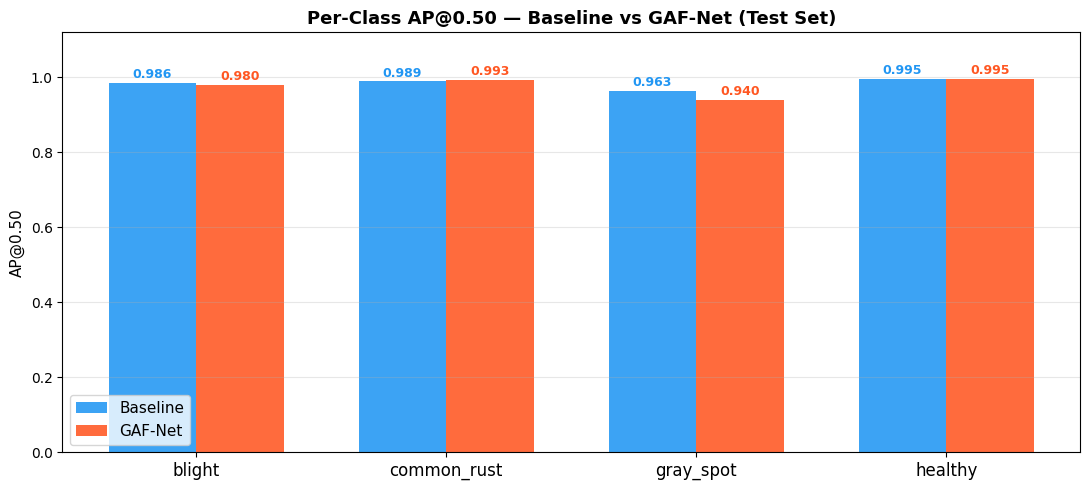

✅ Saved → /kaggle/working/saved_checkpoints/plot_per_class_ap50.png


In [19]:
from ultralytics import YOLO
import numpy as np

CLASS_NAMES = ["blight", "common_rust", "gray_spot", "healthy"]

# Load best weights for each model
base_model_eval = YOLO("/kaggle/working/runs/detect/baseline/weights/best.pt")
gaf_model_eval  = YOLO("/kaggle/working/runs/detect/gafnet_corn/weights/best.pt")

# Run validation (test split)
base_val = base_model_eval.val(data=f"{dataset.location}/data.yaml", split="test", verbose=False)
gaf_val  = gaf_model_eval.val(data=f"{dataset.location}/data.yaml",  split="test", verbose=False)

# Extract per-class AP50
base_ap50 = base_val.box.ap50   # shape: (num_classes,)
gaf_ap50  = gaf_val.box.ap50

x      = np.arange(len(CLASS_NAMES))
width  = 0.35

fig, ax = plt.subplots(figsize=(11, 5))
b1 = ax.bar(x - width/2, base_ap50, width, label="Baseline", color=C_BASE, alpha=0.88)
b2 = ax.bar(x + width/2, gaf_ap50,  width, label="GAF-Net",  color=C_GAF,  alpha=0.88)

for bar in b1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=9, color=C_BASE, fontweight="bold")
for bar in b2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=9, color=C_GAF, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, fontsize=12)
ax.set_ylim(0, 1.12)
ax.set_ylabel("AP@0.50", fontsize=11)
ax.set_title("Per-Class AP@0.50 — Baseline vs GAF-Net (Test Set)",
             fontsize=13, fontweight="bold")
ax.legend(fontsize=11)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
perclass_path = "/kaggle/working/saved_checkpoints/plot_per_class_ap50.png"
plt.savefig(perclass_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"✅ Saved → {perclass_path}")

### 9h — List All Saved Plots

In [20]:
print("\n📁 All saved plots:")
for f in sorted(Path("/kaggle/working/saved_checkpoints").glob("*.png")):
    size_kb = f.stat().st_size / 1024
    print(f"  {f.name:<50}  {size_kb:.1f} KB")


📁 All saved plots:
  plot_full_dashboard.png                             583.0 KB
  plot_loss_curves.png                                306.7 KB
  plot_map_curves.png                                 84.1 KB
  plot_metrics_bar_comparison.png                     50.7 KB
  plot_per_class_ap50.png                             51.8 KB
  plot_precision_recall.png                           95.4 KB
